> **Earlier exploratory experiments. This is not the final analysis.**
>
> This notebook records the experiments that came before the final notebook, `eatthis_gluten_project1_final.ipynb`. It is kept for the deep learning work on **dish photos** (a pretrained image network, MobileNetV2, used frozen and then fine-tuned), a **frozen sentence-embedding model** for dish names, and a **blend of text and photo**.
>
> - Its results on test recipes are saved in `earlier_experiments_recipe_results.csv` in this folder.
> - Its restaurant sections (Steps 17 to 20) use an earlier, uncorrected list of restaurant items. Those restaurant results are **superseded** by the final notebook and should not be relied on.
> - It needs a GPU and takes considerably longer to run than the final notebook.

# EatThis gluten screen: Project 1

**15.071 The AI Edge.**

**The question.** A group of friends is choosing a restaurant and one of them avoids gluten. Can EatThis use each restaurant's menu to rank the shortlist by how many dishes are likely free of wheat?

**What this notebook does**

- **Part 1** trains a text model on recipes. For each dish name it estimates the chance of nine gluten ingredient groups (bread, pasta, soy sauce and so on), then combines them into one **gluten risk score**.
- **Part 2** tests whether dish photos add anything, using a pretrained image network, frozen and fine-tuned.
- **Part 3** tests on nine restaurants' official allergen guides, adds a small **menu model** that learns from real menus, and asks the business question: does ranking restaurants by these scores help a group choose?

**What we recommend.** Use the scores to **rank restaurants for a shortlist**, as a pilot. Do **not** use them to clear individual dishes: about one in ten unflagged items still contains wheat.

**How to read the results.** This was exploratory work: we made design choices while looking at results, including on the test recipes, so the recipe test scores may be slightly optimistic. The restaurant results in Part 3, where each restaurant is scored by a model that never saw it, are the fairest evidence.

### How to run it

1. Go to [colab.research.google.com](https://colab.research.google.com), choose **File**, then **Upload notebook**, and pick this file.
2. Choose **Runtime**, then **Change runtime type**, pick **L4 GPU** and click Save.
3. Choose **Runtime**, then **Run all**.
4. Within a few seconds, Step 2 shows a box. Paste your Kaggle key and press Enter.
5. Wait about 40 to 50 minutes. Results appear under each grey box as it finishes.
6. Step 5b may ask you to upload the Epicurious file if Kaggle cannot provide it. If you do not have it, click **Cancel upload** and that check is skipped.

Each grey box is called a **cell**. It holds a short piece of code, which is a set of instructions for the computer. You do not need to change any of them. The text above each cell says what it does and how to read its result.

When you finish, choose **Runtime**, then **Disconnect and delete runtime**, so the GPU stops using credits.

## Step 1. Load the tools

These lines load free, standard toolkits for tables, models and charts. Nothing is shown when this step works.

In [1]:
import ast, glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option("display.max_colwidth", 90)
np.random.seed(0)

import sklearn, sys as _sys
print(f"Python {_sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}")

Python 3.13.16, pandas 2.2.3, numpy 2.4.6, scikit-learn 1.6.1


## Step 2. Sign in to Kaggle

Kaggle is the website that hosts the recipe photos and the extra recipes. A box appears below. Paste your Kaggle key into it and press **Enter**. What you paste stays hidden and is not saved in this notebook.

Treat the key like a password: do not share it outside your team.

In [2]:
%pip install -q -U kagglehub
from getpass import getpass
import kagglehub

kaggle_key = getpass("Paste your Kaggle key here, then press Enter: ").strip()
os.environ["KAGGLE_API_TOKEN"] = kaggle_key
try:
    from kagglehub.config import set_kaggle_api_token
    set_kaggle_api_token(kaggle_key)
except ImportError:
    pass
del kaggle_key
print("Key received.")

Paste your Kaggle key here, then press Enter: ··········
Kaggle credentials set.
Key received.


## Step 3. Load the recipes

About 13,500 recipes collected from Epicurious. Each has a title, an ingredient list and a photo. These recipes are used both to train the models and, through a locked-away test set, to grade them.

Source: *Food Ingredients and Recipes Dataset with Images* (Kaggle), listed as CC BY-SA 3.0.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/NewsAppsUMD/recipe-dataset/main/13k-recipes.csv"

recipes = pd.read_csv(DATA_URL)
recipes = recipes.dropna(subset=["Title"]).reset_index(drop=True)
recipes["ingredients"] = recipes["Cleaned_Ingredients"].apply(ast.literal_eval)

print("Recipes loaded:", len(recipes))
recipes[["Title", "ingredients"]].head(3)

Recipes loaded: 13496


,Title,ingredients
0,Miso-Butter Roast Chicken With Acorn Squash Panzanella,"[1 (3½–4-lb.) whole chicken, 2¾ tsp. kosher salt, divided, plus more, 2 small acorn sq..."
1,Crispy Salt and Pepper Potatoes,"[2 large egg whites, 1 pound new potatoes (about 1 inch in diameter), 2 teaspoons kosh..."
2,Thanksgiving Mac and Cheese,"[1 cup evaporated milk, 1 cup whole milk, 1 tsp. garlic powder, 1 tsp. onion powder, 1..."


## Step 4. The gluten answer key, by ingredient group

The recipes do not say whether they contain gluten, so we work it out from each ingredient list.

- `GLUTEN_GROUPS`: nine groups of ingredients that contain gluten. If any word in a group appears in an ingredient, the recipe contains that group.
- `EXCEPTIONS`: phrases that contain a gluten word but are not gluten, such as "rice flour". They are removed first.
- Any part of an ingredient line described as gluten-free is ignored. A line is split at commas, "and" and "or" first, so "gluten-free soy sauce and wheat flour" still counts the wheat flour.

These labels come from a rule, not from a laboratory or a dietitian. They are a reasonable stand-in for the truth, not clinical ground truth.

**This is the list for teammates to review.** To change it, edit the words between the quotation marks and run the notebook again.

In [4]:
GLUTEN_GROUPS = {
    'wheat flour': [
        'flour', 'wheat', 'gluten', 'semolina', 'durum', 'farina',
        'spelt', 'farro', 'kamut', 'einkorn', 'triticale', 'matzo',
        'matzoh', 'seitan', 'graham',
    ],
    'bread and buns': [
        'bread', 'toast', 'crostini', 'baguette', 'brioche', 'challah',
        'ciabatta', 'focaccia', 'sourdough', 'pumpernickel', 'flatbread', 'cornbread',
        'pita', 'naan', 'lavash', 'bagel', 'croissant', 'english muffin',
        'bun', 'tortilla', 'stuffing', 'crouton',
    ],
    'breadcrumbs': [
        'breadcrumb', 'panko',
    ],
    'pasta and noodles': [
        'pasta', 'noodle', 'spaghetti', 'linguine', 'fettuccine', 'tagliatelle',
        'pappardelle', 'bucatini', 'capellini', 'angel hair', 'penne', 'rigatoni',
        'ziti', 'fusilli', 'farfalle', 'orecchiette', 'macaroni', 'ditalini',
        'orzo', 'fregola', 'lasagna', 'lasagne', 'ravioli', 'tortellini',
        'gnocchi', 'vermicelli', 'ramen', 'udon', 'soba', 'couscous',
    ],
    'pastry and dough': [
        'puff pastry', 'phyllo', 'filo', 'kataifi', 'pie crust', 'piecrust',
        'pie dough', 'pastry dough', 'pizza dough', 'bread dough', 'wonton', 'gyoza',
        'dumpling wrapper', 'egg roll wrapper',
    ],
    'cookies, crackers and cake': [
        'cracker', 'pretzel', 'biscuit', 'cookie', 'vanilla wafer', 'chocolate wafer',
        'wafer cookie', 'oreo', 'cupcake', 'pancake', 'donut', 'doughnut',
        'angel food cake', 'sponge cake', 'ladyfinger', 'pound cake', 'cake mix', 'pancake mix',
        'bisquick', 'shortbread', 'gingerbread',
    ],
    'barley, rye and bulgur': [
        'barley', 'rye', 'bulgur', 'freekeh', 'malt', 'malted',
    ],
    'soy sauce and similar': [
        'soy sauce', 'teriyaki', 'hoisin',
    ],
    'beer': [
        'beer', 'ale', 'lager', 'stout',
    ],
}

EXCEPTIONS = [
    'rice flour', 'almond flour', 'coconut flour', 'chickpea flour',
    'garbanzo flour', 'gram flour', 'corn flour', 'cornflour',
    'masa flour', 'tapioca flour', 'potato flour', 'buckwheat flour',
    'oat flour', 'sorghum flour', 'teff flour', 'cassava flour',
    'quinoa flour', 'millet flour', 'soy flour', 'hazelnut flour',
    'chestnut flour', 'nut flour', 'arrowroot flour', 'plantain flour',
    'mochiko', 'corn tortilla', 'tortilla chip', 'rice noodle',
    'rice stick noodle', 'rice vermicelli', 'glass noodle', 'cellophane noodle',
    'bean thread noodle', 'mung bean noodle', 'shirataki noodle', 'kelp noodle',
    'zucchini noodle', 'sweet potato noodle', 'rice cracker', 'rice cake',
    'rye whiskey', 'rye whisky', 'ginger ale', 'ginger beer',
    'root beer', 'bread-and-butter pickle', 'bread and butter pickle', 'breadfruit',
    'cookie cutter', 'biscuit cutter', 'cookie sheet', 'cookie/biscuit cutter',
    'biscuit or cookie cutter', 'cookie or biscuit cutter', 'cookie scoop', 'cupcake liner',
    'cupcake pan', 'cupcake tin', 'cupcake paper', 'buckwheat pancake mix',
    'rye or bourbon', 'bourbon or rye',
]

def as_pattern(words):
    # Match whole words, with an optional plural ending.
    return re.compile(r"\b(" + "|".join(re.escape(w) + r"(?:s|es)?" for w in words) + r")\b")

GROUP_NAMES = list(GLUTEN_GROUPS)
GROUP_PATTERNS = {g: as_pattern(words) for g, words in GLUTEN_GROUPS.items()}
EXCEPTION_PATTERN = as_pattern(EXCEPTIONS)
GLUTEN_FREE = re.compile(r"gluten[\s-]*free")

def groups_found(lines):
    # Return the set of gluten groups found in a list of ingredient lines.
    parts = [p for l in lines for p in re.split(r",|;|\band\b|\bor\b", str(l).lower())]
    texts = [EXCEPTION_PATTERN.sub(" ", p) for p in parts if not GLUTEN_FREE.search(p)]
    return {g for g, p in GROUP_PATTERNS.items() if any(p.search(t) for t in texts)}

def label(df, ingredient_column):
    # Add one 0/1 column per group, and a gluten column that is 1 if any group is present.
    found = df[ingredient_column].apply(groups_found)
    for g in GROUP_NAMES:
        df[g] = found.apply(lambda s: int(g in s))
    df["gluten"] = df[GROUP_NAMES].max(axis=1)
    return df

## Step 5. Label every recipe

**How to read the result:** the share of recipes containing gluten, then the share containing each group. A recipe can contain several groups. The sample shows which groups were found, so you can judge whether the answer key behaves sensibly.

In [5]:
recipes = label(recipes, "ingredients")

print(f"Share of recipes containing gluten: {recipes['gluten'].mean():.0%}\n")
print(recipes[GROUP_NAMES].mean().map("{:.1%}".format).to_string())
recipes["groups"] = recipes[GROUP_NAMES].apply(lambda r: ", ".join(g for g in GROUP_NAMES if r[g]), axis=1)
recipes.sample(8, random_state=7)[["Title", "gluten", "groups"]]

Share of recipes containing gluten: 45%

wheat flour                   22.7%
bread and buns                11.1%
breadcrumbs                    2.0%
pasta and noodles              5.8%
pastry and dough               2.6%
cookies, crackers and cake     2.9%
barley, rye and bulgur         1.6%
soy sauce and similar          5.0%
beer                           1.0%


,Title,gluten,groups
2122,Chicken and Root Vegetable Pot Pie,1,"wheat flour, pastry and dough"
2253,Cabbage Stir-Fry With Coconut and Lemon,0,
9759,Belgian Leek Tart with Aged Goat Cheese (Flamiche Aux Poireaux),1,wheat flour
6825,Muesli Bread,0,
11733,Crab and Herb Fettucine,1,pasta and noodles
13447,Golden Pancakes with Pecorino and Prosciutto,1,wheat flour
12050,"Braised Lamb Shanks with Coriander, Fennel, and Star Anise",0,
1803,Autumn Leaves Cupcake Wreath,1,"cookies, crackers and cake"


## Step 5b. Checking the answer key against Epicurious editors

A separate Epicurious collection of about 20,000 recipes carries editors' tags, including **"wheat/gluten-free"**. We apply our answer key to those recipes' ingredient lists and ask: of the recipes the editors tagged gluten-free, how many does our key also call gluten-free?

This checks **one side only**. Editors tag some gluten-free recipes and leave the rest untagged, so an untagged recipe tells us nothing. It cannot show whether our key catches every recipe that does contain gluten. That is what the manual check below is for.

The notebook first tries to load the collection from Kaggle ("Epicurious - Recipes with Rating and Nutrition", file full_format_recipes.json). If that fails, it asks you to upload the zip file. If neither works, this check is skipped and says so.

In [6]:
import json, zipfile, io
epi = None
try:
    folder = kagglehub.dataset_download("hugodarwood/epirecipes")
    epi = json.load(open(glob.glob(os.path.join(folder, "**", "full_format_recipes.json"), recursive=True)[0]))
    print("Loaded from Kaggle.")
except Exception as problem:
    print("Kaggle did not provide the file:", repr(problem)[:120])
    try:
        from google.colab import files
        print("Upload the Epicurious zip file (or click Cancel upload to skip this check).")
        up = files.upload()
        if up:
            z = zipfile.ZipFile(io.BytesIO(next(iter(up.values()))))
            epi = json.loads(z.read([n for n in z.namelist() if n.endswith("full_format_recipes.json")][0]))
    except Exception as problem2:
        print("Upload failed:", repr(problem2)[:120])

if epi is None:
    print("SKIPPED: the label check did not run because the Epicurious file was not available.")
else:
    usable = [r for r in epi if isinstance(r, dict) and r.get("title") and r.get("ingredients") and isinstance(r.get("categories"), list)]
    check = pd.DataFrame({"title": [r["title"].strip() for r in usable],
                          "editor_gluten_free": ["wheat/gluten-free" in [c.lower() for c in r["categories"]] for r in usable],
                          "key_groups": [groups_found(r["ingredients"]) for r in usable]}).drop_duplicates("title")
    check["key_gluten"] = check["key_groups"].str.len() > 0
    tagged = check[check["editor_gluten_free"]]
    print(f"Recipes with a title, ingredients and tags: {len(check):,} (of {len(epi):,} in the file)")
    print(f"Tagged gluten-free by editors: {len(tagged):,}")
    print(f"Of those, our key also says no gluten: {(~tagged['key_gluten']).sum():,} ({(~tagged['key_gluten']).mean():.1%})")
    disagree = tagged[tagged["key_gluten"]]
    print("\nA sample of disagreements, to judge who is right:")
    display(disagree.sample(min(15, len(disagree)), random_state=1)[["title", "key_groups"]])

100%|██████████| 11.3M/11.3M [00:01<00:00, 6.50MB/s]

Extracting files...


Loaded from Kaggle.
Recipes with a title, ingredients and tags: 17,740 (of 20,130 in the file)
Tagged gluten-free by editors: 4,357
Of those, our key also says no gluten: 4,174 (95.8%)

A sample of disagreements, to judge who is right:


,title,key_groups
4346,Egg Curry with Tomatoes and Cilantro,{bread and buns}
9287,"Roast Chickens with Pistachio Salsa, Peppers, and Corn",{bread and buns}
12196,"Baked Eggs with Merguez Sausage, Tomatoes, and Smoky Paprika",{bread and buns}
19336,Corn-Bread and Chorizo Stuffing,{bread and buns}
3589,"Mozzarella, Tomato, and Ham Layered Sandwiches",{bread and buns}
17644,New England Sausage Stuffing with Maple Corn Bread,{bread and buns}
2365,"Braised Rotisserie Chicken With Bacon, Tomatoes, and Kale",{bread and buns}
19318,Chipotle-Glazed Ribs,{bread and buns}
15429,Chana Masala,{pasta and noodles}
12395,Picadillo Tostadas,{bread and buns}


### Manual check of both sides

The cell below writes **label_audit_sample.csv**: 60 recipes our key says contain gluten and 60 it says do not, with extra weight on recipes where an exception word applied. A teammate reads each ingredient list and writes yes or no in the empty column. This tests both kinds of label error, which the editors' tags cannot.

In [7]:
exception_hit = recipes["ingredients"].apply(lambda ls: any(EXCEPTION_PATTERN.search(str(l).lower()) for l in ls))
pos = recipes[recipes["gluten"] == 1].sample(60, random_state=1)
neg_ex = recipes[(recipes["gluten"] == 0) & exception_hit].sample(min(20, int(((recipes["gluten"] == 0) & exception_hit).sum())), random_state=1)
neg = pd.concat([neg_ex, recipes[(recipes["gluten"] == 0) & ~exception_hit].sample(60 - len(neg_ex), random_state=1)])
audit = pd.concat([pos, neg]).sample(frac=1, random_state=2)
audit = audit.assign(ingredients=audit["ingredients"].apply("; ".join), our_label=audit["gluten"].map({1: "contains gluten", 0: "no gluten"}),
                     groups_found=audit["groups"], reviewer_says_contains_gluten="", reviewer_note="")
audit[["Title", "ingredients", "our_label", "groups_found", "reviewer_says_contains_gluten", "reviewer_note"]].to_csv("label_audit_sample.csv", index=False)
print("Saved label_audit_sample.csv with", len(audit), "recipes for manual review.")

Saved label_audit_sample.csv with 120 recipes for manual review.


## Step 6. Split the recipes into three groups

A model must be judged on recipes it has never seen, in the same way an exam uses new questions.

- **Training set (70%)**: the models learn from these.
- **Validation set (15%)**: used to choose settings and the cut-off.
- **Test set (15%)**: used to report results.

**Duplicates stay together.** Some recipes appear more than once, under the same title or with an identical ingredient list. If one copy were in training and another in the test, the test would be too easy. So we first link recipes that share a normalised title, an identical ingredient list or a valid photo file, including chains of links (if A shares a title with B, and B shares ingredients with C, all three are linked), and keep each linked group in one set.

We made design choices while looking at results on these recipes, so treat the test results as exploratory rather than a single untouched exam.

In [8]:
def normalise(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(text).lower())).strip()

parent = list(range(len(recipes)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
keys = {"title": recipes["Title"].map(normalise),
        "ingredients": recipes["Cleaned_Ingredients"].map(normalise),
        "photo": recipes["Image_Name"].where(~recipes["Image_Name"].astype(str).str.contains("#NAME"), None)}
for key in keys.values():
    for _, idx in key.dropna().groupby(key.dropna()).groups.items():
        idx = list(idx)
        for j in idx[1:]:
            parent[find(j)] = find(idx[0])
recipes["dup_group"] = [find(i) for i in range(len(recipes))]
group_label = recipes.groupby("dup_group")["gluten"].max()
print(f"{len(recipes)} recipes in {len(group_label)} groups; {int((recipes.groupby('dup_group').size() > 1).sum())} groups have more than one recipe")

train_g, rest_g = train_test_split(group_label.index, test_size=0.30, random_state=42, stratify=group_label.values)
valid_g, test_g = train_test_split(rest_g, test_size=0.50, random_state=42, stratify=group_label.loc[rest_g].values)
recipes["split"] = np.where(recipes["dup_group"].isin(train_g), "train", np.where(recipes["dup_group"].isin(valid_g), "valid", "test"))
train, valid, test = (recipes[recipes["split"] == s] for s in ("train", "valid", "test"))

shared = set(train["Title"].map(normalise)) & set(test["Title"].map(normalise))
print(f"Test titles also found in training after grouping: {len(shared)}")

for name, part in [("Training", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:<11}{len(part):>6} recipes, {part['gluten'].mean():.0%} contain gluten")

13496 recipes in 13278 groups; 180 groups have more than one recipe
Test titles also found in training after grouping: 0
Training     9451 recipes, 45% contain gluten
Validation   2026 recipes, 45% contain gluten
Test         2019 recipes, 46% contain gluten


## Step 7. Add 500,000 extra training recipes (RecipeNLG)

RecipeNLG is a public collection of about 2.2 million recipes with names and ingredients but no photos. We add a random 500,000 to the **training** recipes only, so the text model meets far more dish names. In an earlier run (before the fixes in Steps 4 and 6) this cut false alarms per 1,000 test dishes from about 300 to about 233.

Two safeguards keep the test fair. The validation and test recipes do not change, and any RecipeNLG recipe whose normalised name matches one of them is removed. Near-duplicates under different names can still slip through, so the model cannot have seen an exam question in advance.

The download is about 600 MB. If this step fails for any reason, the notebook carries on with the Epicurious recipes alone and says so.

In [9]:
EXTRA_RECIPES = 500_000

try:
    nlg_folder = kagglehub.dataset_download("paultimothymooney/recipenlg")
    nlg_file = max(glob.glob(os.path.join(nlg_folder, "**", "*.csv"), recursive=True), key=os.path.getsize)
    extra = pd.read_csv(nlg_file, usecols=["title", "ingredients"]).dropna()
    extra = extra.sample(min(EXTRA_RECIPES, len(extra)), random_state=42)
    held_out = set(pd.concat([valid["Title"], test["Title"]]).map(normalise))
    extra = extra[~extra["title"].map(normalise).isin(held_out)].rename(columns={"title": "Title"})
    def parse_list(s):
        for reader in (json.loads, ast.literal_eval):
            try:
                value = reader(s)
                if isinstance(value, list):
                    return value
            except Exception:
                pass
        return str(s).strip("[]").split('", "')
    extra["ingredient_lines"] = extra["ingredients"].apply(parse_list)
    extra = label(extra, "ingredient_lines")
    print(f"Extra training recipes added: {len(extra):,}, of which {extra['gluten'].mean():.0%} contain gluten")
except Exception as problem:
    extra = train.iloc[0:0]
    print("The extra recipes could not be added, so training uses the Epicurious recipes only.")
    print("Please copy this message to Claude:", repr(problem))

text_train = pd.concat([train[["Title", "gluten"] + GROUP_NAMES], extra[["Title", "gluten"] + GROUP_NAMES]], ignore_index=True)
print(f"Total training recipes for the text model: {len(text_train):,}")

Using Colab cache for faster access to the 'recipenlg' dataset.
Extra training recipes added: 493,097, of which 51% contain gluten
Total training recipes for the text model: 502,548


## Step 8. Two simple rules with no AI

The benchmarks every model has to beat.

- **Approach 0, always flag:** warn about every dish. It never misses gluten, but it is useless because it warns about everything.
- **Approach 1, word rule:** flag a dish only if its *name* contains a gluten word, such as "Garlic Bread".

In [10]:
def word_rule(texts):
    return np.array([int(len(groups_found([t])) > 0) for t in texts])

## Step 9. Text model, step 1: which gluten ingredients are likely?

The model reads only the dish name. It turns each name into numbers recording which words and word pairs it contains, then trains one small model per ingredient group, nine in all. Each learns, for example, that "stir-fry" raises the chance of soy sauce and "lasagna" the chance of pasta.

This takes a few minutes because of the extra recipes.

**How to read the result:** the **ROC-AUC** for each group on the validation recipes. ROC-AUC is the chance that the model gives a randomly chosen recipe containing the group a higher score than one without it: 0.5 is no better than guessing and 1.0 is perfect.

In [11]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = vectorizer.fit_transform(text_train["Title"])

group_models = {}
for g in GROUP_NAMES:
    group_models[g] = LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train[g])

def text_groups(texts):
    # One column per group: the chance that this dish contains that group.
    X = vectorizer.transform(list(texts))
    return pd.DataFrame({g: group_models[g].predict_proba(X)[:, 1] for g in GROUP_NAMES})

valid_groups = text_groups(valid["Title"])
for g in GROUP_NAMES:
    print(f"{g:<28} ROC-AUC {roc_auc_score(valid[g], valid_groups[g]):.3f}   ({valid[g].sum()} validation recipes contain it)")

wheat flour                  ROC-AUC 0.922   (467 validation recipes contain it)
bread and buns               ROC-AUC 0.890   (230 validation recipes contain it)
breadcrumbs                  ROC-AUC 0.896   (44 validation recipes contain it)
pasta and noodles            ROC-AUC 0.977   (118 validation recipes contain it)
pastry and dough             ROC-AUC 0.968   (54 validation recipes contain it)
cookies, crackers and cake   ROC-AUC 0.874   (43 validation recipes contain it)
barley, rye and bulgur       ROC-AUC 0.934   (35 validation recipes contain it)
soy sauce and similar        ROC-AUC 0.918   (101 validation recipes contain it)
beer                         ROC-AUC 0.850   (23 validation recipes contain it)


## Step 10. Text model, step 2: so how likely is gluten?

Every group contains gluten, so a dish contains gluten if at least one group is present. We combine the nine group estimates with the formula 1 − (1 − p₁) × (1 − p₂) × … . If the groups were independent this would be the chance that at least one is present, but they are not (flour, bread and breadcrumbs often go together), so we call the result a **gluten risk score**, not a probability. Higher means more likely.

We also keep the strongest group as the **possible source**. It is a guess at where gluten might come from, not a verified explanation.

For comparison we train one more model the direct way, straight from dish name to gluten in one step, which is how the earlier version worked.

**How to read the result:** a few example dishes with their risk score and possible source.

In [12]:
def gluten_from_groups(groups):
    return 1 - np.prod(1 - groups[GROUP_NAMES].values, axis=1)

def possible_source(groups):
    top = groups[GROUP_NAMES].idxmax(axis=1)
    chance = groups[GROUP_NAMES].max(axis=1)
    return [f"{g} ({c:.0%})" if c >= 0.2 else "no clear source" for g, c in zip(top, chance)]

direct_model = LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train["gluten"])
def text_direct(texts):
    return direct_model.predict_proba(vectorizer.transform(list(texts)))[:, 1]

examples = ["Beef and Broccoli Stir-Fry", "Chicken Noodle Soup", "Garlic Bread", "Fried Mussels", "Potato Salad", "Flourless Chocolate Cake"]
eg = text_groups(examples)
pd.DataFrame({"dish": examples, "risk score": gluten_from_groups(eg), "possible source": possible_source(eg)}) \
  .style.format({"risk score": "{:.2f}"}).hide(axis="index")

dish,risk score,possible source
Beef and Broccoli Stir-Fry,0.93,soy sauce and similar (92%)
Chicken Noodle Soup,0.99,pasta and noodles (99%)
Garlic Bread,0.97,bread and buns (96%)
Fried Mussels,0.55,wheat flour (39%)
Potato Salad,0.01,no clear source
Flourless Chocolate Cake,0.02,no clear source


## Step 10b. A deep language model for the text

The text model above only knows whole words it has seen in training. A deep language model reads words in pieces and has learned from a very large amount of English text, so an unfamiliar name such as "künefe" or "brik" can still land near "pastry" or "cheese pie".

We use **all-MiniLM-L6-v2**, a small, free pretrained language model (a transformer, a type of deep neural network). As with the image model, we keep it **frozen**: it turns each dish name into 384 numbers capturing its meaning, and we train one small model per ingredient group on those numbers.

Each group then gets two opinions, one from the word counts and one from the language model. A tiny final model per group, trained on the validation recipes, decides how much to trust each.

This takes about five minutes on a GPU. If it fails for any reason, the notebook carries on with the word-count model and says so.

**How to read the result:** the ROC-AUC of the gluten likelihood on the validation recipes, before and after adding the language model.

In [13]:
def odds(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

try:
    %pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer
    language_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda" if __import__("torch").cuda.is_available() else "cpu")

    def meaning(texts):
        return language_model.encode(list(texts), batch_size=512, normalize_embeddings=True, show_progress_bar=False)

    E_train = meaning(text_train["Title"])
    deep_group_models = {g: LogisticRegression(C=10, max_iter=1000).fit(E_train, text_train[g]) for g in GROUP_NAMES}
    del E_train

    def deep_only_groups(texts):
        E = meaning(texts)
        return pd.DataFrame({g: deep_group_models[g].predict_proba(E)[:, 1] for g in GROUP_NAMES})

    # Per group, learn on the validation recipes how to weigh the two opinions.
    words_valid, deep_valid = text_groups(valid["Title"]), deep_only_groups(valid["Title"])
    stackers = {g: LogisticRegression(max_iter=1000).fit(np.column_stack([odds(words_valid[g]), odds(deep_valid[g])]), valid[g])
                for g in GROUP_NAMES}

    def text_groups_deep(texts):
        texts = list(texts)
        w, d = text_groups(texts), deep_only_groups(texts)
        return pd.DataFrame({g: stackers[g].predict_proba(np.column_stack([odds(w[g]), odds(d[g])]))[:, 1] for g in GROUP_NAMES})

    best_text_groups = text_groups_deep
    BEST_TEXT = "3b. Text, two steps, with deep language model"
    before = roc_auc_score(valid["gluten"], gluten_from_groups(words_valid))
    after = roc_auc_score(valid["gluten"], gluten_from_groups(text_groups_deep(valid["Title"])))
    print(f"Validation ROC-AUC. Word counts only: {before:.3f}. With the language model: {after:.3f}")
    print("(The validation recipes also trained the weighing step, so the fair comparison is the test set in Step 15.)")
except Exception as problem:
    best_text_groups = text_groups
    BEST_TEXT = "3. Text, two steps (ingredient groups)"
    print("The language model could not be used, so the word-count model carries on alone.")
    print("Please copy this message to Claude:", repr(problem))

Validation ROC-AUC. Word counts only: 0.902. With the language model: 0.903
(The validation recipes also trained the weighing step, so the fair comparison is the test set in Step 15.)


# Part 2. The photo layer

## Step 11. Download the recipe photos

Each recipe has a photo stored on Kaggle (about 250 MB, one or two minutes).

In [14]:
photo_folder = kagglehub.dataset_download("pes12017000148/food-ingredients-and-recipe-dataset-with-images")
photo_files = glob.glob(os.path.join(photo_folder, "**", "*.jpg"), recursive=True)
photo_by_name = {os.path.splitext(os.path.basename(p))[0]: p for p in photo_files}
recipes["photo_path"] = recipes["Image_Name"].map(photo_by_name)
print(f"Recipes with a photo: {recipes['photo_path'].notna().sum()} of {len(recipes)}")

100%|██████████| 206M/206M [00:12<00:00, 17.6MB/s]

Extracting files...


Recipes with a photo: 13466 of 13496


## Step 12. Let a pretrained image model look at every photo

We use **MobileNetV2**, a convolutional neural network (the type covered in Lecture 13) already trained on over a million everyday photos. We remove its last layer and keep a summary of each photo as 1,280 numbers describing shapes, textures and colours. Reusing a trained network this way is **transfer learning**, and leaving its layers unchanged is keeping them **frozen**.

With a GPU this takes two or three minutes; on CPU, about 15 to 20.

In [15]:
import torch
from PIL import Image
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", "GPU (fast)" if device == "cuda" else "CPU (slower, but fine)")

WEIGHTS = MobileNet_V2_Weights.DEFAULT
image_model = mobilenet_v2(weights=WEIGHTS)
image_model.classifier = torch.nn.Identity()
image_model = image_model.eval().to(device)
prepare_photo = WEIGHTS.transforms()

class DishPhotos(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = list(paths)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        try:
            return prepare_photo(Image.open(self.paths[i]).convert("RGB")), 1
        except Exception:
            return prepare_photo(Image.new("RGB", (224, 224))), 0

def photo_numbers(paths):
    loader = torch.utils.data.DataLoader(DishPhotos(paths), batch_size=64, num_workers=2)
    rows, readable = [], []
    with torch.no_grad():
        for batch, ok in loader:
            rows.append(image_model(batch.to(device)).cpu().numpy())
            readable.append(ok.numpy())
    return np.vstack(rows), np.concatenate(readable).astype(bool)

with_photo = recipes[recipes["photo_path"].notna()].copy()
P, readable = photo_numbers(with_photo["photo_path"])
with_photo, P = with_photo[readable], P[readable]
print(f"Photos summarised: {len(with_photo)}, each as {P.shape[1]} numbers")

Running on: GPU (fast)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 180MB/s]


Photos summarised: 13466, each as 1280 numbers


## Step 13. Photo model, both steps

The same two steps as the text: one small model per ingredient group, trained on the photo summaries of the training recipes, then combined into a gluten likelihood.

In [16]:
is_train = (with_photo["split"] == "train").values
is_valid = (with_photo["split"] == "valid").values
is_test = (with_photo["split"] == "test").values

photo_models = {g: make_pipeline(StandardScaler(), LogisticRegression(C=0.001, max_iter=3000)).fit(P[is_train], with_photo.loc[is_train, g])
                for g in GROUP_NAMES}

def photo_groups(numbers):
    return pd.DataFrame({g: photo_models[g].predict_proba(numbers)[:, 1] for g in GROUP_NAMES})

photo_g = photo_groups(P)
photo_score = gluten_from_groups(photo_g)
words_score = gluten_from_groups(text_groups(with_photo["Title"]))
text_g = best_text_groups(with_photo["Title"])
text_score = gluten_from_groups(text_g)
direct_score = text_direct(with_photo["Title"])
answer = with_photo["gluten"].values
print(f"Validation ROC-AUC. Text: {roc_auc_score(answer[is_valid], text_score[is_valid]):.3f}. Photo: {roc_auc_score(answer[is_valid], photo_score[is_valid]):.3f}")

Validation ROC-AUC. Text: 0.903. Photo: 0.739


## Step 13b. Fine-tune the image model

So far MobileNetV2 has been frozen: we only trained a small model on top of its 1,280-number summaries. **Fine-tuning** goes further. We let the last few layers of the network itself adjust to our dish photos, so it can learn what pastry, breading or noodles look like, while the earlier layers that detect edges and textures stay frozen.

With about 9,400 training photos there is a risk the network memorises them instead of learning general patterns (**overfitting**). Three guards:

1. Only the last three of the network's 19 building blocks are retrained.
2. Each photo is shown slightly altered (cropped, flipped) every time, so exact pictures cannot be memorised.
3. After each pass through the photos (an **epoch**), we check the validation photos and keep the best version, stopping when it stops improving.

This needs the GPU, about five to ten minutes. On CPU it would take hours, so it is skipped there.

**How to read the result:** the validation ROC-AUC after each epoch.

In [17]:
import copy
from torchvision import transforms

photo_ft_ready = False
if device != "cuda":
    print("No GPU, so fine-tuning is skipped and the frozen photo model is used.")
else:
    train_look = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                                     transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    plain_look = prepare_photo

    class LabelledPhotos(torch.utils.data.Dataset):
        def __init__(self, frame, look):
            self.paths = frame["photo_path"].tolist()
            self.labels = frame[GROUP_NAMES].values.astype("float32")
            self.look = look
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, i):
            return self.look(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

    torch.manual_seed(0)
    ft_model = mobilenet_v2(weights=WEIGHTS)
    ft_model.classifier = torch.nn.Sequential(torch.nn.Dropout(0.3), torch.nn.Linear(1280, len(GROUP_NAMES)))
    for p in ft_model.features.parameters():
        p.requires_grad = False
    for block in ft_model.features[-3:]:
        for p in block.parameters():
            p.requires_grad = True
    ft_model = ft_model.to(device)

    optimiser = torch.optim.Adam([{"params": ft_model.classifier.parameters(), "lr": 1e-3},
                                  {"params": [p for b in ft_model.features[-3:] for p in b.parameters()], "lr": 1e-4}])
    loss_fn = torch.nn.BCEWithLogitsLoss()
    train_loader = torch.utils.data.DataLoader(LabelledPhotos(with_photo[is_train], train_look), batch_size=64, shuffle=True, num_workers=2)

    def ft_groups(paths):
        ft_model.eval()
        loader = torch.utils.data.DataLoader(DishPhotos(paths), batch_size=128, num_workers=2)
        out = []
        with torch.no_grad():
            for batch, _ in loader:
                out.append(torch.sigmoid(ft_model(batch.to(device))).cpu().numpy())
        return pd.DataFrame(np.vstack(out), columns=GROUP_NAMES)

    best_score, best_state, patience = 0, None, 0
    for epoch in range(1, 9):
        ft_model.train()
        for photos, labels in train_loader:
            optimiser.zero_grad()
            loss = loss_fn(ft_model(photos.to(device)), labels.to(device))
            loss.backward()
            optimiser.step()
        score = roc_auc_score(answer[is_valid], gluten_from_groups(ft_groups(with_photo.loc[is_valid, "photo_path"])))
        print(f"Epoch {epoch}: validation ROC-AUC {score:.3f}")
        if score > best_score:
            best_score, best_state, patience = score, copy.deepcopy(ft_model.state_dict()), 0
        else:
            patience += 1
            if patience == 2:
                print("No improvement for two epochs, so training stops here.")
                break
    ft_model.load_state_dict(best_state)
    photo_ft_g = ft_groups(with_photo["photo_path"])
    photo_ft_score = gluten_from_groups(photo_ft_g)
    photo_ft_ready = True
    print(f"\nValidation ROC-AUC. Frozen: {roc_auc_score(answer[is_valid], photo_score[is_valid]):.3f}. Fine-tuned: {best_score:.3f}")

Epoch 1: validation ROC-AUC 0.712
Epoch 2: validation ROC-AUC 0.731
Epoch 3: validation ROC-AUC 0.739
Epoch 4: validation ROC-AUC 0.748
Epoch 5: validation ROC-AUC 0.745
Epoch 6: validation ROC-AUC 0.746
No improvement for two epochs, so training stops here.

Validation ROC-AUC. Frozen: 0.739. Fine-tuned: 0.748


## Step 14. Combine the menu text and the photo

We use the strongest text model and the strongest photo model. A small final model learns, on the validation recipes, how much to trust each, and blends them into one likelihood.

**How to read the result:** a weight near zero means that source adds little.

In [18]:
best_photo_score = photo_ft_score if photo_ft_ready else photo_score
both_inputs = np.column_stack([odds(text_score), odds(best_photo_score)])
blender = LogisticRegression(max_iter=1000).fit(both_inputs[is_valid], answer[is_valid])
both_score = blender.predict_proba(both_inputs)[:, 1]
print(f"Weight on the menu text: {blender.coef_[0][0]:.2f}")
print(f"Weight on the photo:     {blender.coef_[0][1]:.2f}")

Weight on the menu text: 1.04
Weight on the photo:     0.49


## Step 15. Results on the test recipes

Every approach is graded on the same test recipes (those with a photo). Each learned model has its cut-off set on the validation recipes to catch 95% of gluten dishes, because missing gluten is worse than a false alarm. The two rules have no cut-off to set. The 95% is a target on the validation set, not a guarantee on new data.

Differences of a few dishes per 1,000 are within what chance alone could produce on about 2,000 test recipes.

- **Recall**: of the dishes that truly contain gluten, the share we flagged. Higher is better.
- **False alarm rate**: of the dishes without gluten, the share we flagged anyway. Lower is better.
- **Misses per 1,000** and **False alarms per 1,000**: the same results per 1,000 dishes screened, the number for the pitch.

In [19]:
TARGET_RECALL = 0.95

def cutoff_for_target(scores, truth):
    gluten_scores = np.sort(np.asarray(scores)[np.asarray(truth) == 1])
    return gluten_scores[int(np.floor((1 - TARGET_RECALL) * len(gluten_scores)))]

def summarize(name, flags, truth, scores=None):
    truth, flags = np.asarray(truth), np.asarray(flags)
    misses = int(((flags == 0) & (truth == 1)).sum())
    false_alarms = int(((flags == 1) & (truth == 0)).sum())
    return {"Approach": name,
            "Recall": 1 - misses / (truth == 1).sum(),
            "False alarm rate": false_alarms / (truth == 0).sum(),
            "Misses per 1,000": 1000 * misses / len(truth),
            "False alarms per 1,000": 1000 * false_alarms / len(truth),
            "ROC-AUC": roc_auc_score(truth, scores) if scores is not None else np.nan}

final_scores = {"2. Text, one step (direct)": direct_score,
                "3. Text, two steps (ingredient groups)": words_score}
if BEST_TEXT.startswith("3b"):
    final_scores[BEST_TEXT] = text_score
final_scores["4. Photo, two steps, frozen"] = photo_score
if photo_ft_ready:
    final_scores["4b. Photo, two steps, fine-tuned"] = photo_ft_score
final_scores["5. Best text and best photo combined"] = both_score
cutoffs = {name: cutoff_for_target(s[is_valid], answer[is_valid]) for name, s in final_scores.items()}

truth = answer[is_test]
rows = [summarize("0. Always flag", np.ones(is_test.sum(), dtype=int), truth),
        summarize("1. Word rule on dish name", word_rule(with_photo.loc[is_test, "Title"]), truth)]
rows += [summarize(name, (s[is_test] >= cutoffs[name]).astype(int), truth, s[is_test]) for name, s in final_scores.items()]
final_results = pd.DataFrame(rows)

print(f"Test recipes: {is_test.sum()}")
final_results.style.format({"Recall": "{:.0%}", "False alarm rate": "{:.0%}", "Misses per 1,000": "{:.0f}",
                            "False alarms per 1,000": "{:.0f}", "ROC-AUC": "{:.3f}"}, na_rep="").hide(axis="index")

Test recipes: 2015


Approach,Recall,False alarm rate,"Misses per 1,000","False alarms per 1,000",ROC-AUC
0. Always flag,100%,100%,0,544,
1. Word rule on dish name,35%,2%,296,9,
"2. Text, one step (direct)",96%,44%,16,237,0.925
"3. Text, two steps (ingredient groups)",96%,43%,16,233,0.922
"3b. Text, two steps, with deep language model",96%,41%,17,222,0.921
"4. Photo, two steps, frozen",95%,76%,22,413,0.752
"4b. Photo, two steps, fine-tuned",96%,75%,19,407,0.751
5. Best text and best photo combined,95%,38%,21,207,0.924


### Where does the photo help most?

The photo should matter most when the dish name is uninformative, so we look at test dishes where the text model was unsure (between 30% and 70%).

In [20]:
unsure = is_test & (text_score >= 0.3) & (text_score <= 0.7)
print(f"Test dishes where the text model was unsure: {unsure.sum()}")
print(f"  ROC-AUC, text alone:      {roc_auc_score(answer[unsure], text_score[unsure]):.3f}")
print(f"  ROC-AUC, text and photo:  {roc_auc_score(answer[unsure], both_score[unsure]):.3f}")

Test dishes where the text model was unsure: 467
  ROC-AUC, text alone:      0.719
  ROC-AUC, text and photo:  0.753


## Step 16. Charts

Three charts for the deck, each also saved as a picture file (folder icon on the left of Colab).

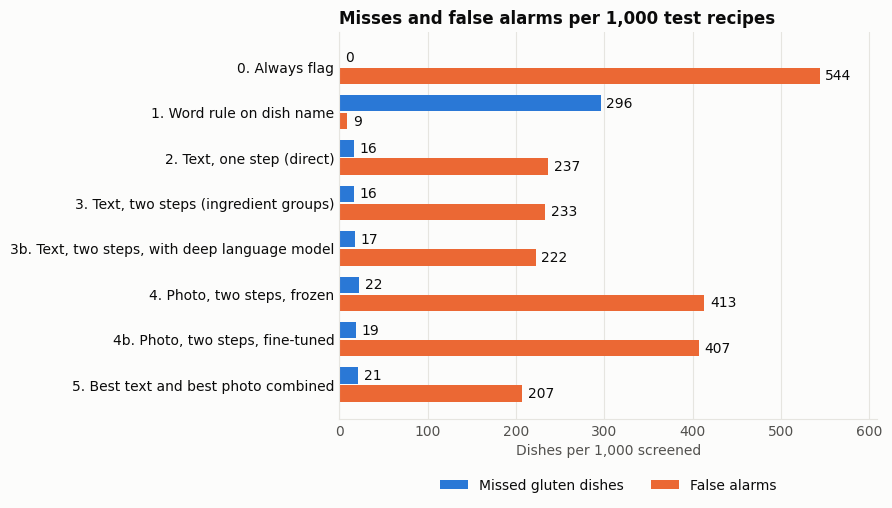

In [21]:
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

# Chart 1: misses and false alarms per 1,000 dishes
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(final_results))[::-1]
h = 0.36
b1 = ax.barh(y + h / 2 + 0.02, final_results["Misses per 1,000"], height=h, color=BLUE, label="Missed gluten dishes")
b2 = ax.barh(y - h / 2 - 0.02, final_results["False alarms per 1,000"], height=h, color=ORANGE, label="False alarms")
ax.bar_label(b1, fmt="%.0f", padding=4, color=INK)
ax.bar_label(b2, fmt="%.0f", padding=4, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(final_results["Approach"], color=INK)
ax.set_xlabel("Dishes per 1,000 screened")
ax.set_xlim(0, final_results[["Misses per 1,000", "False alarms per 1,000"]].values.max() * 1.12)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("Misses and false alarms per 1,000 test recipes", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("chart1_misses_and_false_alarms.png", dpi=200)
plt.show()

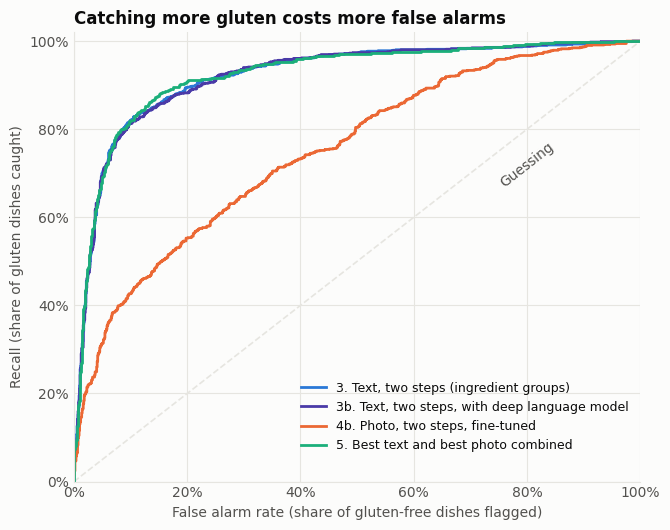

In [22]:
# Chart 2: recall against false alarms at every cut-off
fig, ax = plt.subplots(figsize=(6.8, 5.4))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.2, linestyle="--")
ax.text(0.80, 0.72, "Guessing", color=MUTED, rotation=38, ha="center", va="center")
shown = {k: v for k, v in final_scores.items() if not k.startswith(("2.", "3. ", "4. ")) or k == BEST_TEXT}
shown = {"3. Text, two steps (ingredient groups)": words_score, **shown} if BEST_TEXT.startswith("3b") else shown
for (name, s), colour in zip(shown.items(), [BLUE, VIOLET, ORANGE, AQUA]):
    fa, rc, _ = roc_curve(truth, s[is_test])
    ax.plot(fa, rc, color=colour, linewidth=2, label=name)
ax.set_xlabel("False alarm rate (share of gluten-free dishes flagged)")
ax.set_ylabel("Recall (share of gluten dishes caught)")
ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 0.04), fontsize=9)
ax.set_title("Catching more gluten costs more false alarms", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("chart2_recall_vs_false_alarms.png", dpi=200)
plt.show()

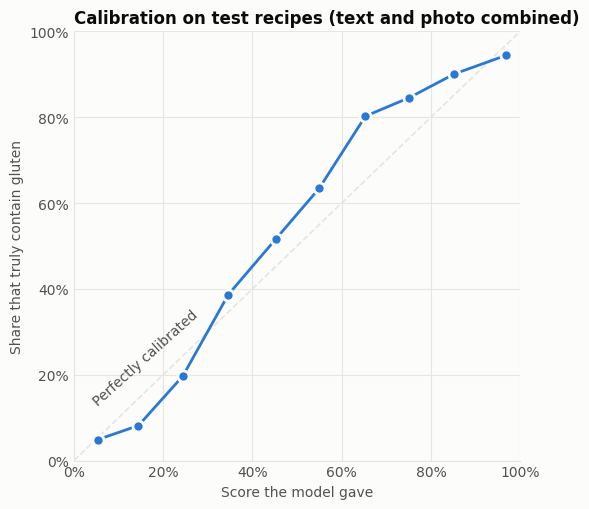

In [23]:
# Chart 3: are the percentages honest? (text and photo combined)
check = pd.DataFrame({"score": both_score[is_test], "gluten": truth})
check["band"] = pd.cut(check["score"], bins=np.linspace(0, 1, 11), include_lowest=True)
bands = check.groupby("band", observed=True).agg(predicted=("score", "mean"), actual=("gluten", "mean"), dishes=("gluten", "size"))
bands = bands[bands["dishes"] >= 20]

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.2, linestyle="--")
ax.text(0.16, 0.24, "Perfectly calibrated", color=MUTED, rotation=42, ha="center", va="center")
ax.plot(bands["predicted"], bands["actual"], color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xlabel("Score the model gave")
ax.set_ylabel("Share that truly contain gluten")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_title("Calibration on test recipes (text and photo combined)", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("chart3_honest_percentages.png", dpi=200)
plt.show()

# Part 3. Real restaurant menus

## Step 17. Nine restaurants' allergen guides

EatThis will score restaurant menus, but the models so far learned from home recipes. Nine chains publish allergen guides that mark every item containing **wheat**. We extracted each guide's table by hand-checked script, leaving out items marked only "may contain" and exact duplicates.

| Restaurant | Guide used (file as downloaded) | Edition |
| --- | --- | --- |
| Tatte | allergen-and-nutritional-guide-fall-v-091826-web.pdf | Fall 2026, updated 18 Sep 2026 |
| Panera Bread | c10-26-allergen-guide.pdf | Dated 4 Nov 2026 |
| Boudin Bakery | Master-Allergen-List_Q4-2026-Cheesesteaks_082726.pdf | Q4 2026, dated 27 Aug 2026 |
| Pret A Manger (US) | Allergen_Guide_September_2026.pdf | September 2026 |
| Cosi | Allergen_and_Nutritionals_Feb_2026.pdf | Stated current as of June 2026 |
| CAVA | KT6_26_AN_ANGUIDE_RETAIL_T_MKTAN11724.pdf | Undated, 2026 menu |
| Au Bon Pain | au-bon-pain-nutrition-fall-2018.pdf | Menu dated 6 Oct 2017 |
| Sweetgreen | sweetgreen.pdf | Undated seasonal menu; only 26 clearly legible items used |
| Chipotle (UK) | Combine-list-022025-UK.pdf | February 2025; lists ingredients, not dishes |

**Wheat is not gluten.** The guides mark wheat. Barley and rye also contain gluten, and every chain warns of cross-contact in its kitchens. So throughout this part, an item "not marked as containing wheat" is exactly that, and never "safe" or "gluten-free".

### Item types, fixed before looking at any model results

To compare like with like, every item gets one type, by the rules below. The rules use only the item's name and the guide's own section headings, never a model score.

- **Drink:** the name contains a drink word (coffee, caffe, latte, tea, juice, smoothie and so on) and no food word (cake, cookie, muffin, bread and so on), or the section is milkshakes.
- **Catering or retail pack:** the name or section says serves, assortment, box, platter, tray, dozen, gift, tube, a pack count such as "(10)", or the section is catering.
- **Component:** an ingredient, topping, side, dressing, dip or sauce rather than a dish someone orders as a meal; or a whole guide that lists only ingredients (Chipotle UK).
- **Dish:** everything else. **Dishes are the main unit of analysis.**

In [24]:
RESTAURANT_ITEMS = [
    # (restaurant, section as printed in the guide or blank, item name, contains wheat per the guide: 1 yes, 0 no)
    ('Boudin', '', 'BLTA', 1),
    ('Boudin', '', 'California Veggie', 1),
    ('Boudin', '', 'Caprese (Vegetarian)', 1),
    ('Boudin', '', 'Catalan (Vegan)', 1),
    ('Boudin', '', 'Catalan (Vegetarian)', 1),
    ('Boudin', '', 'Chicken Salad', 1),
    ('Boudin', '', 'Crispy Chicken Caesar Wrap', 1),
    ('Boudin', '', 'Crispy Chicken Parm', 1),
    ('Boudin', '', 'Deluxe French Dip', 1),
    ('Boudin', '', 'Grilled Brie with Apples & Fig Jam', 1),
    ('Boudin', '', 'Hot Chicken Pesto Sandwich', 1),
    ('Boudin', '', 'Italian Classic', 1),
    ('Boudin', '', 'Prosciutto & Pestos Sandwich', 1),
    ('Boudin', '', 'Sourdough French Dip', 1),
    ('Boudin', '', 'The Great Grilled Cheese', 1),
    ('Boudin', '', 'The Great with Bacon', 1),
    ('Boudin', '', 'Toasted Chicken Club', 1),
    ('Boudin', '', 'Tuna Salad', 1),
    ('Boudin', '', 'Tuna Melt', 1),
    ('Boudin', '', 'Turkey and Havarti', 1),
    ('Boudin', '', 'Turkey Avocado', 1),
    ('Boudin', '', 'Turkey Cranberry', 1),
    ('Boudin', '', 'The Classic Ribeye Cheesesteak', 1),
    ('Boudin', '', 'The Bold Ribeye Cheesesteak', 1),
    ('Boudin', '', 'Rustic Stuffing Turkey Cranberry', 1),
    ('Boudin', '', 'Thanksgiving Turkey Melt on Rustic Stuffing Bread', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Asian Citrus Chicken Salad', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Chicken, Apple, Walnut Salad', 0),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Crispy Chicken Avo Salad', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Little Gem Cobb Salad', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Mixed Greens (Side Salad)', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Mixed Greens (Side Salad, No Croutons)', 0),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Traditional Caesar Salad', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Add On Grilled All-Natural Chicken Breast', 0),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Add On Crispy Fried Chicken Breast', 1),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Green Goddess Chicken With Avocado Protein Bowl', 0),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Harvest Chicken Protein Bowl', 0),
    ('Boudin', 'SALADS & PROTEIN BOWLS (excludes rolls/bread)', 'Mediterranean Chicken W/ Lemon Hummus Protein Bowl', 0),
    ('Boudin', 'SOUPS & CHILI (excludes bread bowl, includes garnish)', 'Broccoli Cheddar', 0),
    ('Boudin', 'SOUPS & CHILI (excludes bread bowl, includes garnish)', 'Butternut Squash', 0),
    ('Boudin', 'SOUPS & CHILI (excludes bread bowl, includes garnish)', 'Chili', 0),
    ('Boudin', 'SOUPS & CHILI (excludes bread bowl, includes garnish)', 'Clam Chowder', 0),
    ('Boudin', 'SOUPS & CHILI (excludes bread bowl, includes garnish)', 'Rustic Tomato', 1),
    ('Boudin', '', 'Cheese Pizza', 1),
    ('Boudin', '', 'Chicken Fingers & French Fries', 1),
    ('Boudin', '', 'Grilled Cheese', 1),
    ('Boudin', '', 'Mac & Cheese', 1),
    ('Boudin', '', 'Turkey Sandwich', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'All Meat', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Cheesy Garlic Bread', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Classic Pepperoni', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Crowd Pleaser (50/50)', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Four Cheese', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Hawaiian Pizza', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', "Papa Steve's Original Style Pizza Bread", 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Sausage & Pepperoni', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Four Cheese Pinsa Romana', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Pepperoni Pinsa Romana', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Prosciutto Bianca Pinsa Romana', 1),
    ('Boudin', 'PIZZA (individual & Papa Steve’s)', 'Sausage & Pepperoni Hot Honey Pinsa Romana', 1),
    ('Boudin', 'MILKSHAKES', 'Cookies & Cream', 1),
    ('Boudin', 'MILKSHAKES', 'Dark Chocolate', 0),
    ('Boudin', 'MILKSHAKES', 'Sea Salt Caramel', 0),
    ('Boudin', 'MILKSHAKES', 'Strawberry', 0),
    ('Boudin', 'MILKSHAKES', '*Seasonal* - Pumpkin Spice', 0),
    ('Boudin', 'BREADS', 'Asiago Cheese', 1),
    ('Boudin', 'BREADS', 'Brioche (Buns & Rolls)', 1),
    ('Boudin', 'BREADS', 'Cinnamon Raisin', 1),
    ('Boudin', 'BREADS', 'Corn Rye', 1),
    ('Boudin', 'BREADS', 'English Muffins', 1),
    ('Boudin', 'BREADS', 'Pinsa Crust - 4 Pack', 1),
    ('Boudin', 'BREADS', 'Schiacciata Flatbread', 1),
    ('Boudin', 'BREADS', 'Sourdough (Loaves, Rolls, Baguettes, Lunch Boxes, Critters & Seasonal Shapes)', 1),
    ('Boudin', 'BREADS', 'Sweet Cinnamon Delight', 1),
    ('Boudin', 'BREADS', 'Multigrain (Loaves & Lunch Boxes)', 1),
    ('Boudin', 'Sides', 'House Fries', 0),
    ('Boudin', 'Sides', 'Spicy Buttermilk Ranch Fries', 0),
    ('Boudin', '', 'Balsamic Dressing', 0),
    ('Boudin', '', 'Basil Pesto Sauce', 0),
    ('Boudin', '', 'Caesar Dressing', 0),
    ('Boudin', '', 'Calabrian Chili Hot Honey', 0),
    ('Boudin', '', 'Citrus, Garlic, & Herb Caesar Dressing', 0),
    ('Boudin', '', 'Dijon Mustard', 0),
    ('Boudin', '', 'Garlic Aioli Spread', 0),
    ('Boudin', '', 'Honey Mustard', 0),
    ('Boudin', '', 'Horseradish Mayo', 0),
    ('Boudin', '', 'Lemon Hummus Dressing', 0),
    ('Boudin', '', 'Lemon Vinaigrette Dressing', 0),
    ('Boudin', '', 'Mayo', 0),
    ('Boudin', '', 'Pesto Balsamic Dressing', 0),
    ('Boudin', '', 'Pesto Mayo', 0),
    ('Boudin', '', 'Ranch Dressing', 0),
    ('Boudin', '', 'Romesco Sauce', 0),
    ('Boudin', '', 'Spicy Asian Dressing', 1),
    ('Boudin', '', 'Spicy Crema', 0),
    ('Boudin', '', 'Sundried Tomato Spread', 0),
    ('Boudin', 'BREAKFAST', 'Bacon & Cheddar on English Muffin', 1),
    ('Boudin', 'BREAKFAST', 'Cali-Style Bacon Breakfast Burrito', 1),
    ('Boudin', 'BREAKFAST', 'Cali-Style Veggie Breakfast Burrito', 1),
    ('Boudin', 'BREAKFAST', 'Granola & Greek Yogurt Parfait', 0),
    ('Boudin', 'BREAKFAST', 'Ham & Swiss on Croissant', 1),
    ('Boudin', 'BREAKFAST SIDES', 'Bacon', 0),
    ('Boudin', 'BREAKFAST SIDES', 'Fruit Cup', 0),
    ('Boudin', 'BREAKFAST SIDES', 'Sourdough Toast', 1),
    ('Boudin', 'BREAKFAST SIDES', 'English Muffin', 1),
    ('Boudin', 'BREAKFAST SIDES', 'Multigrain Toast', 1),
    ('Boudin', 'CATERING LUNCH', 'Traditional Deli Feast', 1),
    ('Boudin', 'CATERING LUNCH', 'Ultimate Deli Feast', 1),
    ('Boudin', 'CATERING LUNCH', 'Duo Salad', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Sausage Frittata Tray', 0),
    ('Boudin', 'CATERING BREAKFAST', 'Vegetarian Frittata Tray', 0),
    ('Boudin', 'CATERING BREAKFAST', 'Vegetarian Frittata Breakfast Sandwich', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Vegan Breakfast Burrito', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Ham & Swiss Breakfast Sandwich on English Muffin', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Egg & Cheddar Breakfast Sandwich on English Muffin', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Chicken & Waffle Breakfast Sandwich', 1),
    ('Boudin', 'CATERING BREAKFAST', 'Oatmeal (Includes condiments)', 0),
    ('Boudin', 'CATERING BREAKFAST', 'Simple Seasoned Eggs', 0),
    ('Boudin', 'CATERING BREAKFAST', 'Avocado Toast Tray', 1),
    ('Boudin', '', 'Bagel - Blueberry', 1),
    ('Boudin', '', 'Bagel - Cinnamon Raisin', 1),
    ('Boudin', '', 'Bagel - Onion', 1),
    ('Boudin', '', 'Bagel - Plain', 1),
    ('Boudin', '', 'Bagel - Sesame', 1),
    ('Boudin', '', 'Bar - Cookies & Cream', 1),
    ('Boudin', '', 'Bar - Double Fudge Brownie', 1),
    ('Boudin', '', 'Bar - "Gluten Friendly" Raspberry Almond Shortbread', 0),
    ('Boudin', '', 'Bar - Peanut Butter Crunch', 1),
    ('Boudin', '', 'Bar - Salted Caramel Pretzel Brownie', 1),
    ('Boudin', '', 'Chocolate Chip Banana Bread - Loaf & Mini', 1),
    ('Boudin', '', 'Cookie - Oatmeal Raisin Spice', 1),
    ('Boudin', '', 'Cookie - Peanut Butter', 1),
    ('Boudin', '', 'Cookie - Semi-Sweet Chocolate Chip', 1),
    ('Boudin', '', 'Cookie - Snickerdoodle', 1),
    ('Boudin', '', 'Cookie - The Royale', 0),
    ('Boudin', '', 'Cookie - White Chocolate Macadamia Nut', 1),
    ('Boudin', '', 'Croissant - Almond Lg. & Mini (NorCal & SoCal)', 1),
    ('Boudin', '', 'Croissant - Butter Lg. & Mini (NorCal & SoCal)', 1),
    ('Boudin', '', 'Croissant - Chocolate Lg. & Mini (NorCal & SoCal)', 1),
    ('Boudin', '', 'Loaf - Banana Pecan', 1),
    ('Boudin', '', 'Loaf - Marble Chocolate Chip', 1),
    ('Boudin', '', 'Loaf - Seasonal Pumpkin Swirl', 1),
    ('Boudin', '', 'Mini Coffee Cake', 1),
    ('Boudin', '', 'Morning Bun Lg. & Mini', 1),
    ('Boudin', '', 'Muffin - Banana Walnut', 1),
    ('Boudin', '', 'Muffin - Blueberry', 1),
    ('Boudin', '', 'Muffin - Iced Lemon Poppyseed', 1),
    ('Boudin', '', 'Scone - Artisan Blueberry', 1),
    ('Boudin', '', 'Scone - Artisan Cinnamon', 1),
    ('Boudin', 'GRAZE & Gather', 'Fruits & Cheese Tray', 1),
    ('Boudin', 'GRAZE & Gather', 'California Vegetable Tray', 0),
    ('Boudin', 'GRAZE & Gather', 'Antipasti', 1),
    ('Boudin', 'CATERING SANDWICHES', 'Ham & Swiss', 1),
    ('Boudin', 'CATERING SANDWICHES', 'Pesto Roast Beef', 1),
    ('Boudin', 'CATERING SANDWICHES', 'Roast Beef & Cheddar', 1),
    ('Boudin', 'CATERING SANDWICHES', 'Catering Pesto Chicken', 1),
    ('Boudin', 'CATERING SANDWICHES', '*Sandwiches Prepared on Gluten Free Bread', 0),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini California Veggie', 1),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini Chicken Salad', 1),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini Ham & Swiss', 1),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini Italiano', 1),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini Roast Beef & Cheddar', 1),
    ('Boudin', 'MINI CATERING SANDWICHES', 'Mini Turkey Havarti', 1),
    ('Cosi', '', 'Bowl, Adobo Chicken with Avocado', 0),
    ('Cosi', '', 'Bowl, Spicy Meatless Chorizo', 1),
    ('Cosi', '', 'Bowl, Shanghai Chicken', 1),
    ('Cosi', '', 'Bowl, Falafel & Harissa Hummus', 1),
    ('Cosi', '', 'Orange Juice, Large', 0),
    ('Cosi', '', 'Hard Boiled Eggs', 0),
    ('Cosi', '', 'Fruit Cup', 0),
    ('Cosi', '', '"Così", "(Sun and Moon Design)" and related marks are', 0),
    ('Cosi', '', 'Bagel, Asiago (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Jalepeno (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Multi-Grain (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Plain (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Cinnamon Raisin (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Seasame (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Everything (Just Bagels)', 1),
    ('Cosi', '', 'Bagel, Poppy (Just Bagels)', 1),
    ('Cosi', '', 'Bread Slice, Original* (Corporate)', 1),
    ('Cosi', '', 'Bread Slice, Multi Grain* (Corporate)', 1),
    ('Cosi', '', 'Bread Slice, Original* (Franchisee)', 1),
    ('Cosi', '', 'Bread Slice, Multi Grain* (Franchisee)', 1),
    ('Cosi', '', 'Croissant, Butter*', 1),
    ('Cosi', '', 'Crumb Cake, Butter*', 1),
    ('Cosi', '', 'Loaf, Lemon Pound Cake*', 1),
    ('Cosi', '', 'Loaf, Marble Pound Cake*', 1),
    ('Cosi', '', 'Muffin, Blueberry', 1),
    ('Cosi', '', 'Muffin, Lemon Cranberry', 1),
    ('Cosi', '', 'Muffin, Double Chocolate Chip', 1),
    ('Cosi', '', 'Muffin, Apple Cinnamon', 1),
    ('Cosi', '', 'Scone, Blueberry*', 1),
    ('Cosi', '', 'Scone, Orange Cranberry*', 1),
    ('Cosi', '', '*Disclaimer: Manufacturers of our baked products cannot', 0),
    ('Cosi', '', 'Breakfast & Snacks & Tofu', 0),
    ('Cosi', '', 'Cream Cheese, Low-fat', 0),
    ('Cosi', '', 'Cream Cheese, Plain', 0),
    ('Cosi', '', 'Cream Cheese, Veggie', 0),
    ('Cosi', '', 'Brownie Bites, Blondie', 1),
    ('Cosi', '', 'Brownie Bites, Chocolate Chunk*', 1),
    ('Cosi', '', 'Brownie, Blondie*', 1),
    ('Cosi', '', 'Brownie, Chocolate Chunk*', 1),
    ('Cosi', '', 'Cookie, Chocolate Chip*', 1),
    ('Cosi', '', 'Blueberry Smash Lemonade', 0),
    ('Cosi', '', 'Iced Tea', 0),
    ('Cosi', '', 'Iced Tea, Raspberry', 0),
    ('Cosi', '', 'Lemonade', 0),
    ('Cosi', '', 'Mojito Lemonade', 0),
    ('Cosi', '', 'Café Americano', 0),
    ('Cosi', '', 'Cappuccino', 0),
    ('Cosi', '', 'Caramel Latte', 0),
    ('Cosi', '', 'Chai Tea Latte', 0),
    ('Cosi', '', 'Coffee', 0),
    ('Cosi', '', 'Espresso', 0),
    ('Cosi', '', 'Hot Chocolate', 0),
    ('Cosi', '', 'Latte', 0),
    ('Cosi', '', 'Mocha', 0),
    ('Cosi', '', 'Shot in the Dark', 0),
    ('Cosi', '', 'White Hot Chocolate', 0),
    ('Cosi', '', 'Flatbread Pizza', 0),
    ('Cosi', '', 'Cheese', 1),
    ('Cosi', '', 'Margherita Chicken', 1),
    ('Cosi', '', 'Margherita', 1),
    ('Cosi', '', 'Pepperoni', 1),
    ('Cosi', '', 'Kids Flatbread Cheese Pizza', 1),
    ('Cosi', '', 'Kids Flatbread Pepperoni Pizza', 1),
    ('Cosi', '', 'Kids Grape Cup', 0),
    ('Cosi', '', 'Kids Grilled Cheese', 1),
    ('Cosi', '', 'Kids Ham & Cheese', 1),
    ('Cosi', '', 'Kids Mac & Cheese', 1),
    ('Cosi', '', 'Kids Peanut Butter & Jelly', 1),
    ('Cosi', '', 'Kids Turkey Sandwich', 1),
    ('Cosi', '', 'Protein Add-Ons', 0),
    ('Cosi', '', 'Roasted Chicken', 0),
    ('Cosi', '', 'Turkey', 0),
    ('Cosi', '', 'Tofu', 0),
    ('Cosi', '', 'Tuna Salad', 0),
    ('Cosi', '', 'Southwest Adobo Chicken', 0),
    ('Cosi', '', 'Caesar', 1),
    ('Cosi', '', 'Caesar - Chicken', 1),
    ('Cosi', '', 'Cobb', 0),
    ('Cosi', '', 'Mediterranean Salad', 0),
    ('Cosi', '', 'Mandarin Chicken', 1),
    ('Cosi', '', 'Signature', 0),
    ('Cosi', '', 'Salad Dressing (Portion Only)', 0),
    ('Cosi', '', 'Dressing - Adobo Vinaigrette', 0),
    ('Cosi', '', 'Dressing - Caesar', 0),
    ('Cosi', '', 'Dressing - Ginger Sesame', 1),
    ('Cosi', '', 'Dressing - Cosi® Vinaigrette (Balsamic Vinaigrette)', 0),
    ('Cosi', '', 'Dressing - Green Goddess', 0),
    ('Cosi', '', 'Dressing - Sherry Shallot', 0),
    ('Cosi', '', 'Sandwiches & Melts', 0),
    ('Cosi', '', 'Bacon Turkey Cheddar', 1),
    ('Cosi', '', 'Pesto Chicken Melt', 1),
    ('Cosi', '', 'Fiery Chipotle Chicken Melt', 1),
    ('Cosi', '', 'Buffalo Chicken', 1),
    ('Cosi', '', 'Old World Italiano', 1),
    ('Cosi', '', 'Chicken Noodle', 1),
    ('Cosi', '', 'Fire Roasted Vegetable', 0),
    ('Cosi', '', 'French Onion Soup', 1),
    ('Cosi', '', 'Italian Wedding Soup', 1),
    ('Cosi', '', 'Macaroni & Cheese', 1),
    ('Cosi', '', 'Mediterranean Lentil', 0),
    ('Cosi', '', 'New England Clam Chowder', 0),
    ('Cosi', '', 'Turkey Chili', 1),
    ('Cosi', '', 'Tomato Basil', 0),
    ('Cosi', '', 'Chicken & Dumpling', 1),
    ('Cosi', '', 'Bread Slice, Original (Corporate)', 0),
    ('Cosi', '', '3.2 oz 1 220 9 2.5g', 0),
    ('Cosi', '', 'Bread Slice Multigrain (Corporate)', 0),
    ('Cosi', '', '3.2 oz 1 260 9 5g', 0),
    ('Cosi', '', 'Croissant, Butter 3 oz 1 330 140 15g Crumb Cake, Classic 2.75 oz 2 320 140 15g Loaf, Lemon Pound Cake 4.5 oz 1 470 190 21g Loaf, Marble Pound Cake 4 oz 1 450 210 24g Muffin, Blueberry 4 oz 1 400 _ 19g Muffin, Lemon Cranberry 4 oz 1 380 _ 17g Muffin, Double Chocolate Chunk 4 oz 1 400 _ 19g Muffin, Apple Cinnamon 4 oz 1 410 _ 18g Scone, Blueberry 2.5 oz 2 371 170 19g Scone, Cranberry Orange 2.9 oz 2 310 150 16g Bagel, Asiago (Just Bagel) 4 oz. 1 300 25 2.5g Bagel, Cinnamon Raisin (Just Bagel) 4 oz. 1 300 10 1g Bagel, Everything (Just Bagel) 4 oz. 1 290 10 1g Bagel, Jalepeno (Just Bagel) 4 oz. 1 290 15 1.5g Bagel, Multigrain (Just Bagel) 4 oz. 1 290 30 3g Bagel, Plain (Just Bagel) 4 oz. 1 290 10 1g Bagel, Sesame (Just Bagel) 4 oz. 1 290 10 1g', 0),
    ('Cosi', '', 'Turkey Chili (Bowl) 15 oz 1 360 60 7g Turkey Chili (Cup) 8 oz 1 240 45 5g', 0),
    ('Cosi', '', 'Tomato Basil (Bowl) 15 oz 1 600 420 47g', 0),
    ('Cosi', '', 'Tomato Basil (Cup) 8 oz 1 400 280 31g', 0),
    ('Cosi', '', '"Così", "(Sun and Moon Design)" and related', 0),
    ('Panera', '', '•Scroll down', 0),
    ('Panera', '', 'NOTE: Menu items that do "NOT"', 0),
    ('Panera', '', 'NOTE: Many of our', 0),
    ('Panera', '', 'NOTE: * Highly refined oil from', 0),
    ('Panera', '', 'Product', 0),
    ('Panera', '', 'Bagels & Spreads Asiago Cheese', 1),
    ('Panera', '', 'Asiago Everything', 1),
    ('Panera', '', 'Blueberry', 1),
    ('Panera', '', 'Chocolate Chip', 1),
    ('Panera', '', 'Cinnamon Crunch', 1),
    ('Panera', '', 'Cinnamon Swirl & Raisin', 1),
    ('Panera', '', 'Everything', 1),
    ('Panera', '', 'Multigrain Bagel Flat', 1),
    ('Panera', '', 'Plain', 1),
    ('Panera', '', 'Sesame', 1),
    ('Panera', '', 'Plain Cream Cheese Spread', 0),
    ('Panera', '', 'Honey Walnut Cream Cheese Spread', 0),
    ('Panera', '', 'Honey Pecan Cream Cheese Spread', 0),
    ('Panera', '', 'Breads Artisan Ciabatta- Loaf', 1),
    ('Panera', '', 'Black Pepper Focaccia - Round Loaf', 1),
    ('Panera', '', 'Classic White - Loaf', 1),
    ('Panera', '', 'Country Rustic Sourdough - XL Loaf', 1),
    ('Panera', '', 'Croissant', 1),
    ('Panera', '', 'French Baguette', 1),
    ('Panera', '', 'Sourdough Bread Bowl', 1),
    ('Panera', '', 'Tomato Basil - Miche', 1),
    ('Panera', '', 'Whole Grain Lahvash Wrap', 1),
    ('Panera', '', 'Italian Stuffer Roll - Retail whole', 1),
    ('Panera', '', 'Baked Goods Brownie', 1),
    ('Panera', '', 'Cookie- Candy', 1),
    ('Panera', '', 'Cookie- Chocolate Chipper (Large & Petites)', 1),
    ('Panera', '', 'Cookie - Chocolate Coconut Macaroon', 1),
    ('Panera', '', 'Cookie - Coconut Macaroon', 1),
    ('Panera', '', 'Cookie - Dubai Style Chocolate Pistachio', 1),
    ('Panera', '', 'Cookie- Iced Shaped Shortbread- Pumpkin & Mitten', 1),
    ('Panera', '', 'Cookie- Kitchen Sink', 1),
    ('Panera', '', 'Cookie- Oatmeal Raisin with Berries', 1),
    ('Panera', '', 'Pastry - Cranberry Orange Loaf Slice - Naturally Flavored', 1),
    ('Panera', '', 'Muffin- Blueberry', 1),
    ('Panera', '', 'Muffie- Chocolate Chip', 1),
    ('Panera', '', 'Pastry - Almond', 1),
    ('Panera', '', 'Pastry - Asiago Croissant Twists', 1),
    ('Panera', '', 'Pastry - Cherry', 1),
    ('Panera', '', 'Pastry- Chocolate Croissant', 1),
    ('Panera', '', 'Pastry- Cinnamon Roll', 1),
    ('Panera', '', 'Pastry - Pumpkin Spice Cinnamon Roll', 1),
    ('Panera', '', 'Pastry- Pecan Braid', 1),
    ('Panera', '', 'Scone- Orange (Large & Mini)', 1),
    ('Panera', '', 'Cookie - PB & J', 1),
    ('Panera', '', 'Pastry - Cinnamon Croissant Bites with White Icing', 1),
    ('Panera', '', 'Add on - White Icing Portion Cup', 0),
    ('Panera', '', 'Pastry - Cocoa Marshmallow Flavored Cake Slice', 1),
    ('Panera', '', 'Breakfast- Egg Sandwiches, Souffles, Parfait, Fruit & Oatmeal Asiago Bagel Stack - Sausage & Egg', 1),
    ('Panera', '', 'Asiago Everything Bagel Stack - Wake-up BLT', 1),
    ('Panera', '', 'Asiago Bagel Stack - Farmhouse Duo', 1),
    ('Panera', '', 'Bacon, Egg & Cheese on Artisan Ciabatta', 1),
    ('Panera', '', 'Bacon, Egg & Cheese on Croissant', 1),
    ('Panera', '', 'Bacon Double Take on Black Pepper Focaccia', 1),
    ('Panera', '', 'Chipotle Chicken, Egg & Avo on Artisan Ciabatta', 1),
    ('Panera', '', 'Egg & Cheese on Artisan Ciabatta', 1),
    ('Panera', '', 'Egg & Cheese on Croissant', 1),
    ('Panera', '', 'Egg Styles - Scrambled Egg or Egg White', 0),
    ('Panera', '', 'Garden Avo & Egg White on Multigrain Bagel Flat', 1),
    ('Panera', '', 'Ham Croissant Benny', 1),
    ('Panera', '', 'Ham, Egg & Cheese on Artisan Ciabatta', 1),
    ('Panera', '', 'Sausage, Egg & Cheese on Artisan Ciabatta', 1),
    ('Panera', '', 'Sausage, Egg & Cheese on Croissant', 1),
    ('Panera', '', 'Steak & Wake on Artisan Ciabatta', 1),
    ('Panera', '', 'Four Cheese Souffle', 1),
    ('Panera', '', 'Spinach & Bacon Souffle', 1),
    ('Panera', '', 'Fruit Cup', 0),
    ('Panera', '', 'Hard Boiled Eggs', 0),
    ('Panera', '', 'Parfait- Greek Yogurt with Berries', 0),
    ('Panera', '', 'Steel Cut Oatmeal with Strawberries & Pecans', 0),
    ('Panera', '', 'Steel Cut Oatmeal with Strawberries - Without Pecans', 0),
    ('Panera', '', 'Salads & Stuffers Asian Sesame with & without Chicken', 1),
    ('Panera', '', 'Stuffer - Asian Sesame with & without Chicken', 1),
    ('Panera', '', 'Asian Sesame with & without Chicken - Without Almonds', 1),
    ('Panera', '', 'Stuffer - Asian Sesame with & without Chicken - without Almonds', 1),
    ('Panera', '', 'Caesar with & without Chicken', 1),
    ('Panera', '', 'Stuffer - Caesar with & without Chicken', 1),
    ('Panera', '', 'Stuffer - Farmhouse Crunch', 1),
    ('Panera', '', 'Farmhouse Crunch Salad - without almonds', 0),
    ('Panera', '', 'Stuffer - Farmhouse Crunch - without almonds', 1),
    ('Panera', '', 'Fuji Apple with & without Chicken', 0),
    ('Panera', '', 'Stuffer - Fuji Apple with & without Chicken', 1),
    ('Panera', '', 'Fuji Apple with & without Chicken - Without Pecans', 0),
    ('Panera', '', 'Stuffer - Fuji Apple with & without Chicken - without Pecans', 1),
    ('Panera', '', 'Greek with & without Chicken', 0),
    ('Panera', '', 'Stuffer - Greek with & without Chicken', 1),
    ('Panera', '', 'Green Goddess Cobb with Chicken', 0),
    ('Panera', '', 'Stuffer - Green Goddess Cobb with Chicken', 1),
    ('Panera', '', 'Ranch Parm BLT', 1),
    ('Panera', '', 'Stuffer - Ranch Parm BLT', 1),
    ('Panera', '', 'Southwest Chicken Ranch', 0),
    ('Panera', '', 'Stuffer - Southwest Chicken Ranch', 1),
    ('Panera', '', 'Ultimate Garden Steak Salad', 1),
    ('Panera', '', 'Stuffer - Ultimate Garden Steak', 1),
    ('Panera', '', 'Harvest Medley with and without Chicken', 1),
    ('Panera', '', 'Stuffer- Harvest Medley with and without Chicken', 1),
    ('Panera', '', 'Harvest Medley with and without Chicken - No Pecans', 1),
    ('Panera', '', 'Stuffer- Harvest Medley with and without Chicken - No Pecans', 1),
    ('Panera', '', 'Market Bowls All-In Veggie', 1),
    ('Panera', '', 'Sesame Ginger Chicken', 1),
    ('Panera', '', 'Sesame Ginger Chicken - No Almonds', 1),
    ('Panera', '', 'Carnitas Elote', 0),
    ('Panera', '', 'Sandwiches- Information is provided with default bread choice. If bread choice is Asiago Bagel Stack - Chicken Roma', 1),
    ('Panera', '', 'Asiago Bagel Stack - Spicy Steak', 1),
    ('Panera', '', 'Bacon Turkey Bravo on Tomato Basil', 1),
    ('Panera', '', 'Chicken Bacon Rancher on Black Pepper Focaccia', 1),
    ('Panera', '', 'Chipotle Chicken Avo Melt on Round Black Pepper Focaccia', 1),
    ('Panera', '', 'Ciabatta Cheesesteak', 1),
    ('Panera', '', 'Cranberry Walnut Chicken Salad on Country Rustic', 1),
    ('Panera', '', 'Grilled Cheese on Classic White Loaf', 1),
    ('Panera', '', 'Grilled Chicken & Avo BLT on Country Rustic Sourdough', 1),
    ('Panera', '', 'Mediterranean Veggie on Tomato Basil', 1),
    ('Panera', '', 'Pickle Spear for cold sandwiches', 0),
    ('Panera', '', 'Smokehouse BBQ Chicken on Artisan Ciabatta', 1),
    ('Panera', '', 'Toasted Frontega Chicken on Black Pepper Focaccia', 1),
    ('Panera', '', 'Toasted Italiano on Baguette', 1),
    ('Panera', '', 'Tomato Basil BLT on Tomato Basil Miche', 1),
    ('Panera', '', 'Toasted Caprese Focaccia', 1),
    ('Panera', '', 'Tuna Salad on Country Rustic Sourdough', 1),
    ('Panera', '', 'Turkey & Cheddar on Country Rustic Sourdough', 1),
    ('Panera', '', 'Spicy Fiesta Chicken on Ciabatta', 1),
    ('Panera', '', 'Catering- Ham & Cheddar on Country Rustic', 1),
    ('Panera', '', 'Ciabatta Dipper - French', 1),
    ('Panera', '', 'Ciabatta Dipper - Chicken Pesto', 1),
    ('Panera', '', 'Dressings, Sauces, Spreads & Soup Dipper Sauce - Apple Cider BBQ', 0),
    ('Panera', '', 'Dressing - Asian Sesame vinaigrette', 0),
    ('Panera', '', 'Sauce - Balsamic Glaze', 0),
    ('Panera', '', 'Sauce - Balsamic Vinaigrette', 0),
    ('Panera', '', 'Sauce - Bravo Signature', 0),
    ('Panera', '', 'Dressing - Caesar', 0),
    ('Panera', '', 'Sauce - Cheese Hollandaise', 0),
    ('Panera', '', 'Sauce - Chipotle Aioli', 0),
    ('Panera', '', 'Dressing - Creamy Garden Herb', 0),
    ('Panera', '', 'Sauce - Creamy Basil Pesto', 0),
    ('Panera', '', 'Dressing - Farmhouse Ranch', 0),
    ('Panera', '', 'Sauce - Garlic Aioli', 0),
    ('Panera', '', 'Dressing - Greek', 0),
    ('Panera', '', 'Sauce - Green Chile Salsa Verde', 0),
    ('Panera', '', 'Dressing - Green Goddess', 0),
    ('Panera', '', 'Spread- Hummus', 0),
    ('Panera', '', 'Sauce - Mayonnaise', 0),
    ('Panera', '', 'Dressing - Sesame Ginger', 1),
    ('Panera', '', 'Dressing - White Balsamic Apple Flavored Vinaigrette', 0),
    ('Panera', '', 'Dressing - Zesty Smoky Lemon Vinaigrette', 1),
    ('Panera', '', 'Dipper - Creamy Tomato - Dipper Portion', 0),
    ('Panera', '', 'Dipper - Bistro French Onion - Dipper Portion', 1),
    ('Panera', '', 'Drinks Additional Pump of Caramel Syrup', 0),
    ('Panera', '', 'Additional Pump of Chocolate Sauce', 0),
    ('Panera', '', 'Additional Pump of Chocolatey Hazelnut Flavored Syrup', 0),
    ('Panera', '', 'Additional Pump of Madagascar Vanilla Syrup or Cane Sugar Syrup', 0),
    ('Panera', '', 'Additional Shot of Pumpkin Spice Sauce', 0),
    ('Panera', '', 'Additional Pump of Snickerdoodle Syrup', 0),
    ('Panera', '', 'Additional Pump of White Chocolate and Peppermint Flavored Sauce', 0),
    ('Panera', '', 'Additional Pump of White Chocolate and Pistachio Flavored Sauce', 0),
    ('Panera', '', 'Agave Lemonade', 0),
    ('Panera', '', 'Americano', 0),
    ('Panera', '', 'Blackberry Hibiscus Iced Tea - Naturally Flavored Herbal Tea', 0),
    ('Panera', '', 'Cafe Frozen Java', 0),
    ('Panera', '', 'Caffe Latte (espresso - Hot or Iced)', 0),
    ('Panera', '', 'Cappuccino (espresso)', 0),
    ('Panera', '', 'Caramel Latte (espresso - Hot or Iced)', 0),
    ('Panera', '', 'Chai Tea Latte (Hot or Iced)', 0),
    ('Panera', '', 'Cherry Lime Fresca', 0),
    ('Panera', '', 'Coffee/Decaf Coffee (Hot or Iced)', 0),
    ('Panera', '', 'Dragonfruit Sunset Energy Refresher - Naturally Flavored', 0),
    ('Panera', '', 'Hot Tea Bags', 0),
    ('Panera', '', 'Iced Teas - Unsweetened / Sweetened / Passion Papaya Naturally Flavored Green Tea', 0),
    ('Panera', '', 'Island Mango Energy Refresher - Naturally Flavored - With Dragon Fruit', 0),
    ('Panera', '', 'Island Mango Energy Refresher - Naturally Flavored - With Pineapple', 0),
    ('Panera', '', 'Madagascar Vanilla Latte (espresso - Hot or Iced)', 0),
    ('Panera', '', 'Mango Smoothie with Greek Yogurt (Frozen)', 0),
    ('Panera', '', 'Mocha Latte (espresso - Hot or Iced)', 0),
    ('Panera', '', 'Passionfruit Paradise Energy Refresher - Naturally Flavored', 0),
    ('Panera', '', 'Pumpkin Spice Frozen Java', 0),
    ('Panera', '', 'Pumpkin Spice Iced Coffee', 0),
    ('Panera', '', 'Pumpkin Spice Latte - (Hot or Iced)', 0),
    ('Panera', '', 'Pistachio White Mocha Frozen Java', 0),
    ('Panera', '', 'Pistachio White Mocha Latte', 0),
    ('Panera', '', 'Pistachio White Mocha Iced Latte', 0),
    ('Panera', '', 'Pistachio White Mocha Iced Coffee', 0),
    ('Panera', '', 'Signature Hot Chocolate - (Hot or Frozen)', 0),
    ('Panera', '', 'Strawberry Banana Smoothie with Greek Yogurt (Frozen)', 0),
    ('Panera', '', 'Strawberry Basil Lemonade Fresca', 0),
    ('Panera', '', 'Strawberry Smoothie with Greek Yogurt (Frozen)', 0),
    ('Panera', '', 'Sweet Cream Cold Foam', 0),
    ('Panera', '', 'Tropical Green Smoothie (Frozen)', 0),
    ('Panera', '', 'Kids Broccoli Cheddar Soup - Cup', 1),
    ('Panera', '', 'Grilled Cheese on Classic White Loaf - Whole', 1),
    ('Panera', '', 'Kids Ham & American Cheese on Classic White Loaf - Whole', 1),
    ('Panera', '', 'Kids Turkey & American Cheese on Classic White Loaf - Whole', 1),
    ('Panera', '', 'Mac & Cheese - Cup', 1),
    ('Panera', '', 'Soups & Mac Bistro French Onion with Cheese & Croissant Croutons', 1),
    ('Panera', '', 'Broccoli Cheddar', 1),
    ('Panera', '', 'Cream of Chicken & Wild Rice', 1),
    ('Panera', '', 'Homestyle Chicken Noodle', 1),
    ('Panera', '', 'Creamy Tomato with Croissant Croutons - Vegetarian', 1),
    ('Panera', '', 'Bacon Mac & Cheese', 1),
    ('Panera', '', 'Mac & Cheese', 1),
    ('Panera', '', 'Rustic Baked Potato', 0),
    ('Panera', '', 'Three Cheese Lasagna', 1),
    ('Panera', '', 'Autumn Squash - Vegetarian', 0),
    ('Panera', '', 'Non-traditional Grab N Go Chicken Caesar Wrap', 1),
    ('Panera', '', 'Frontega Chicken Wrap', 1),
    ('Panera', '', 'Green Goddess Chicken Wrap', 1),
    ('Panera', '', 'Turkey & Cheddar Wrap', 1),
    ('Pret', '', 'Baguettes', 0),
    ('Pret', '', 'Pesto Caprese Baguette', 1),
    ('Pret', '', "Pret's Chicken Bánh Mi", 1),
    ('Pret', '', 'Pret’s Famous Ham & Cheese Baguette', 1),
    ('Pret', '', "Pret's Tuna & Cucumber Baguette", 1),
    ('Pret', '', 'Romesco Chicken & Mozzarella Baguette', 1),
    ('Pret', '', 'Sandwiches', 0),
    ('Pret', '', 'Cheddar & Tomato Sandwich', 1),
    ('Pret', '', 'Chicken & Bacon Sandwich', 1),
    ('Pret', '', "Pret's Chicken Salad & Avo Sandwich", 1),
    ('Pret', '', "Pret's Egg Salad & Arugula Sandwich", 1),
    ('Pret', '', "Pret's Tuna & Cucumber Sandwich", 1),
    ('Pret', '', 'Rainbow Veggie Sandwich', 1),
    ('Pret', '', 'Turkey & Cheddar Sandwich', 1),
    ('Pret', '', "Kid's Ham & Cheddar Sandwich", 1),
    ('Pret', '', "Kid's Cheddar & Mayo Sandwich", 1),
    ('Pret', '', 'Rolls', 0),
    ('Pret', '', 'Avocado Veggie Sandwich', 1),
    ('Pret', '', 'Pret’s Italian Turkey Club Sandwich', 1),
    ('Pret', '', 'Hot Melts', 0),
    ('Pret', '', 'BBQ Pulled Pork Melt', 1),
    ('Pret', '', 'Buffalo Chicken Melt', 1),
    ('Pret', '', 'Roasted Mushroom & Swiss Melt', 1),
    ('Pret', '', 'Wraps', 0),
    ('Pret', '', 'Bang Bang Chicken Wrap', 1),
    ('Pret', '', 'Crunchy Chipotle Chicken & Avo Wrap', 1),
    ('Pret', '', 'Crunchy Miso Mushroom Wrap', 1),
    ('Pret', '', 'Falafel & Hummus Wrap', 1),
    ('Pret', '', 'Spicy Chicken Caesar Wrap', 1),
    ('Pret', '', 'Hot Wraps', 0),
    ('Pret', '', 'Pret’s Chicken Parm Wrap', 1),
    ('Pret', '', "Pret's Pulled Pork Burrito", 1),
    ('Pret', '', 'Spiced Lentil & Chickpea Hot Wrap', 1),
    ('Pret', '', 'Chicken Burrito Wrap', 1),
    ('Pret', '', 'Hot Food', 0),
    ('Pret', '', 'Ham & Cheddar Croissant', 1),
    ('Pret', '', 'Turkey & Swiss Croissant', 1),
    ('Pret', '', 'Broccoli Cheddar & Chive Quiche', 1),
    ('Pret', '', 'Spinach & Fontina Quiche', 1),
    ('Pret', '', 'Bread Roll', 1),
    ('Pret', '', 'Soup', 0),
    ('Pret', '', 'Chili Yogurt & Herbs Soup Topper', 1),
    ('Pret', '', 'Croutons, Lemon & Herbs Soup Topper', 1),
    ('Pret', '', 'Moroccan Lentil Soup', 0),
    ('Pret', '', 'Roasted Veggie Harvest Soup', 0),
    ('Pret', '', 'Super Greens Soup', 0),
    ('Pret', '', 'Tomato & Feta Soup', 0),
    ('Pret', '', 'Turmeric Chicken & Farro Soup', 1),
    ('Pret', '', 'White Chicken Chili', 0),
    ('Pret', '', 'Classic Mac and Cheese', 1),
    ('Pret', '', 'Spinach & Tomato Mac and Cheese', 1),
    ('Pret', '', 'Pumpkin Bisque', 0),
    ('Pret', '', 'Salad', 0),
    ('Pret', '', "Blackened Salmon, Avo & Quinoa Salad with Pret's Simple", 0),
    ('Pret', '', 'Vinaigrette', 0),
    ('Pret', '', 'Blackened Salmon, Avo & Quinoa Salad without Dressing', 0),
    ('Pret', '', "Chicken Avocado Salad with Pret's Simple Vinaigrette", 0),
    ('Pret', '', 'Chicken Avocado Salad without Dressing', 0),
    ('Pret', '', 'Chicken Caesar Salad with Caesar Dressing', 1),
    ('Pret', '', 'Chicken Caesar Salad without Dressing', 1),
    ('Pret', '', 'Chicken, Elote Corn & Avocado Salad with Herb Yogurt Dressing', 0),
    ('Pret', '', "Elote Chicken salad with Pret's Simple Vinaigrette (LAX)", 0),
    ('Pret', '', 'Chicken, Elote Corn & Avocado Salad without Dressing', 0),
    ('Pret', '', "Chicken & Strawberry Salad with Pret's Simple Vinaigrette", 0),
    ('Pret', '', 'Chicken & Strawberry Salad without Dressing', 0),
    ('Pret', '', "Mediterranean Mezze Salad with Pret's Simple Vinaigrette", 0),
    ('Pret', '', 'Mediterranean Mezze Salad without Dressing', 0),
    ('Pret', '', "Pesto Marinated White Bean & Avocado Salad with Pret's Simple", 0),
    ('Pret', '', 'Vinaigrette Pesto Marinated White Bean & Avocado Salad without Dressing', 0),
    ('Pret', '', 'Caesar Side Salad with Caesar Dressing', 1),
    ('Pret', '', 'Caesar Side Salad without Dressing', 1),
    ('Pret', '', "Pret's Greek Side Salad with Herb Yogurt Dressing", 1),
    ('Pret', '', "Pret's Greek Side Salad without Dressing", 1),
    ('Pret', '', "Lemon Arugula Side Salad with Pret's Simple Vinaigrette", 0),
    ('Pret', '', 'Lemon Arugula Side Salad without Dressing', 0),
    ('Pret', '', 'Salad Dressing', 0),
    ('Pret', '', 'Caesar Dressing', 1),
    ('Pret', '', 'Herb Yogurt Dressing', 0),
    ('Pret', '', "Pret's Simple Vinaigrette", 0),
    ('Pret', '', 'Sandwiches. Rolls and Wraps', 0),
    ('Pret', '', 'Egg Salad & Avocado Breakfast Baguette', 1),
    ('Pret', '', 'Bacon, Egg & Cheddar Roll', 1),
    ('Pret', '', 'Egg & Cheddar Roll', 1),
    ('Pret', '', 'Southwestern Breakfast Wrap', 1),
    ('Pret', '', 'Southwestern Breakfast Wrap with bacon', 1),
    ('Pret', '', 'Porridge', 0),
    ('Pret', '', 'Apple Cranberry Crunch Porridge Topper', 0),
    ('Pret', '', 'Coconut Banana Blueberry Porridge Topper', 0),
    ('Pret', '', 'Oatm*lk Porridge', 0),
    ('Pret', '', 'Egg White Greek Frittata', 0),
    ('Pret', '', 'Power Breakfast Frittata', 0),
    ('Pret', '', 'Trial Items- WTC, 179 Broadway, USQ, Fulton, Broadway and Thomas', 0),
    ('Pret', '', 'Dragon Fruit Yogurt Protein Pot', 0),
    ('Pret', '', 'Sunset Smoothie Pot', 0),
    ('Pret', '', 'Egg Salad & Bacon Sourdough Breakfast Baguette', 1),
    ('Pret', '', 'Bacon, Egg & Cheddar Sourdough Breakfast Half Baguette', 1),
    ('Pret', '', 'Egg & Cheddar Sourdough Breakfast Half Baguette', 1),
    ('Pret', '', 'Roasted Tomato & Mozzarella Croissant', 1),
    ('Pret', '', 'Apple Cinnamon Oatm*lk Porridge', 1),
    ('Pret', '', 'Brown Sugar & Banana Oatm*lk Porridge', 1),
    ('Pret', '', 'Fruit', 0),
    ('Pret', '', 'Banana', 0),
    ('Pret', '', 'Cantaloupe & Blueberry Pot', 0),
    ('Pret', '', 'Pineapple & Lime Pot', 0),
    ('Pret', '', 'Strawberry & Blueberry Pot', 0),
    ('Pret', '', 'Pots', 0),
    ('Pret', '', 'Banana & Honey Yogurt Pot (LAX Only)', 0),
    ('Pret', '', 'Berry Yogurt Parfait Pot (LAX ONLY)', 0),
    ('Pret', '', 'Bircher Muesli', 0),
    ('Pret', '', 'Blueberry & Granola Pot', 0),
    ('Pret', '', 'Blueberry Yogurt Pot', 0),
    ('Pret', '', 'Dragon Fruit Coconut Chia Bowl', 0),
    ('Pret', '', 'Egg & Spinach Pot', 0),
    ('Pret', '', 'Guava Coconut Chia Pot', 0),
    ('Pret', '', 'Hummus Pot', 0),
    ('Pret', '', 'Little Cup of Goodness', 0),
    ('Pret', '', 'Strawberry Yogurt Pot', 0),
    ('Pret', '', 'Chobani Strawberry Yogurt Protein Pot', 0),
    ('Pret', '', 'Sunshine Bowl', 0),
    ('Pret', '', "Kid's Honey Banana Yogurt Pot (NYC Only)", 0),
    ('Pret', '', 'Pumpkin Spice Yogurt Pot', 0),
    ('Pret', '', 'Croissanterie', 0),
    ('Pret', '', 'Almond Croissant', 1),
    ('Pret', '', 'Chocolate Croissant', 1),
    ('Pret', '', 'Plain Croissant', 1),
    ('Pret', '', 'Blueberry Muffin', 1),
    ('Pret', '', 'Cinnamon Kouign Amann ("queen a-mahn")', 1),
    ('Pret', '', 'Everything Cream Cheese Swirl', 1),
    ('Pret', '', 'Chocolate Chunk Cookie', 1),
    ('Pret', '', 'Chocolate Brownie Cookie', 1),
    ('Pret', '', 'Double Chocolate Pecan Cookie', 1),
    ('Pret', '', 'Harvest Cookie', 1),
    ('Pret', '', 'Pumpkin Cheese Danish', 1),
    ('Pret', '', 'Sweet Treats', 0),
    ('Pret', '', 'Brownie Bite', 1),
    ('Pret', '', 'Key Lime Cheesecake', 1),
    ('Pret', '', 'Raspberry Cheesecake', 1),
    ('Pret', '', 'Tiramisu Cheesecake', 1),
    ('Pret', '', 'Chocolate Covered Almonds', 0),
    ('Pret', '', 'Omega-3 Mix', 0),
    ('Pret', '', 'Raw Almonds', 0),
    ('Pret', '', 'F riendy', 0),
    ('Pret', '', 'Coffee', 0),
    ('Pret', '', 'Americano Black', 0),
    ('Pret', '', 'Cappuccino (Almond Milk)', 0),
    ('Pret', '', 'Cappuccino (Oat Milk)', 0),
    ('Pret', '', 'Cappuccino (Half and Half)', 0),
    ('Pret', '', 'Cappuccino (Skim Milk)', 0),
    ('Pret', '', 'Cappuccino (Whole Milk)', 0),
    ('Pret', '', 'Espresso', 0),
    ('Pret', '', 'Macchiato (Almond Milk)', 0),
    ('Pret', '', 'Macchiato (Oat Milk)', 0),
    ('Pret', '', 'Macchiato (Half and Half)', 0),
    ('Pret', '', 'Macchiato (Skim Milk)', 0),
    ('Pret', '', 'Macchiato (Whole Milk)', 0),
    ('Pret', '', 'Flat White (Almond Milk)', 0),
    ('Pret', '', 'Flat White (Oat Milk)', 0),
    ('Pret', '', 'Flat White (Half and Half)', 0),
    ('Pret', '', 'Flat White (Skim Milk)', 0),
    ('Pret', '', 'Flat White (Whole Milk)', 0),
    ('Pret', '', 'Coffee (Cont.)', 0),
    ('Pret', '', 'Mocha (Almond Milk)', 0),
    ('Pret', '', 'Mocha (Oat Milk)', 0),
    ('Pret', '', 'Mocha (Half & Half)', 0),
    ('Pret', '', 'Mocha (Skim Milk)', 0),
    ('Pret', '', 'Mocha (Whole Milk)', 0),
    ('Pret', '', 'Latte (Almond Milk)', 0),
    ('Pret', '', 'Latte (Oat Milk)', 0),
    ('Pret', '', 'Latte (Half & Half)', 0),
    ('Pret', '', 'Latte (Skim Milk)', 0),
    ('Pret', '', 'Latte (Whole Milk)', 0),
    ('Pret', '', "Pret's Organic Single Origin Coffee Black", 0),
    ('Pret', '', "Pret's Organic Classic Blend Coffee Black", 0),
    ('Pret', '', 'Other Hot Drinks', 0),
    ('Pret', '', 'Chai Latte (Almond Milk)', 0),
    ('Pret', '', 'Chai Latte (Oat Milk)', 0),
    ('Pret', '', 'Chai Latte (Half & Half)', 0),
    ('Pret', '', 'Chai Latte (Skim Milk)', 0),
    ('Pret', '', 'Chai Latte (Whole Milk)', 0),
    ('Pret', '', 'Matcha Chai Latte (Almond Milk)', 0),
    ('Pret', '', 'Matcha Chai Latte (Oat Milk)', 0),
    ('Pret', '', 'Matcha Chai Latte (Half & Half Milk)', 0),
    ('Pret', '', 'Matcha Chai Latte (Skim Milk)', 0),
    ('Pret', '', 'Matcha Chai Latte (Whole Milk)', 0),
    ('Pret', '', 'Matcha Latte (Almond milk)', 0),
    ('Pret', '', 'Matcha Latte (Oat milk)', 0),
    ('Pret', '', 'Matcha Latte (Half & Half)', 0),
    ('Pret', '', 'Matcha Latte (Skim Milk)', 0),
    ('Pret', '', 'Matcha Latte (Whole Milk)', 0),
    ('Pret', '', 'Hot Chocolate (Almond Milk)', 0),
    ('Pret', '', 'Hot Chocolate (Oat Milk)', 0),
    ('Pret', '', 'Hot Chocolate (Half & Half)', 0),
    ('Pret', '', 'Hot Chocolate (Skim Milk)', 0),
    ('Pret', '', 'Hot Chocolate (Whole Milk)', 0),
    ('Pret', '', 'Iced Coffee', 0),
    ('Pret', '', 'Cold Brew (Black)', 0),
    ('Pret', '', 'Iced Americano (Black)', 0),
    ('Pret', '', 'Iced Coffee (Black)', 0),
    ('Pret', '', 'Iced Espresso (Black)', 0),
    ('Pret', '', 'Iced Mocha (Almond Milk)', 0),
    ('Pret', '', 'Iced Mocha (Oat Milk)', 0),
    ('Pret', '', 'Iced Mocha (Half & Half)', 0),
    ('Pret', '', 'Iced Mocha (Skim Milk)', 0),
    ('Pret', '', 'Iced Mocha (Whole Milk)', 0),
    ('Pret', '', 'Iced Latte (Almond Milk)', 0),
    ('Pret', '', 'Iced Latte (Oat Milk)', 0),
    ('Pret', '', 'Iced Latte (Half & Half)', 0),
    ('Pret', '', 'Iced Latte (Skim Milk)', 0),
    ('Pret', '', 'Iced Latte (Whole Milk)', 0),
    ('Pret', '', 'Other Iced Drinks', 0),
    ('Pret', '', 'Iced Chai Latte (Almond Milk)', 0),
    ('Pret', '', 'Iced Chai Latte (Oat Milk)', 0),
    ('Pret', '', 'Iced Chai Latte (Half & Half)', 0),
    ('Pret', '', 'Iced Chai Latte (Skim Milk)', 0),
    ('Pret', '', 'Iced Chai Latte (Whole Milk)', 0),
    ('Pret', '', 'Iced Chocolate (Almond Milk)', 0),
    ('Pret', '', 'Iced Chocolate (Oat Milk)', 0),
    ('Pret', '', 'Iced Chocolate (Half & Half)', 0),
    ('Pret', '', 'Iced Chocolate (Skim Milk)', 0),
    ('Pret', '', 'Iced Chocolate (Whole Milk)', 0),
    ('Pret', '', 'Iced Matcha (Almond Milk)', 0),
    ('Pret', '', 'Iced Matcha (Oat Milk)', 0),
    ('Pret', '', 'Iced Matcha (Half & Half)', 0),
    ('Pret', '', 'Iced Matcha (Skim Milk)', 0),
    ('Pret', '', 'Iced Matcha (Whole Milk)', 0),
    ('Pret', '', 'Pink Guava Matcha Iced Latte (Almond', 0),
    ('Pret', '', 'Pink Guava Matcha Iced Latte (Oat Milk)', 0),
    ('Pret', '', 'Other Iced Drinks (Cont.)', 0),
    ('Pret', '', 'Pink Guava Matcha Iced Latte (Half &Half)', 0),
    ('Pret', '', 'Pink Guava Matcha Iced Latte (Skim Milk)', 0),
    ('Pret', '', 'Pink Guava Matcha Iced Latte (Whole', 0),
    ('Pret', '', 'Iced Teas, Lemonade and Refreshers', 0),
    ('Pret', '', 'Iced Black Tea', 0),
    ('Pret', '', 'Iced Green Tea', 0),
    ('Pret', '', 'Sunshine Black Tea', 0),
    ('Pret', '', 'Sunshine Green Tea', 0),
    ('Pret', '', 'Pink Guava Lemonade', 0),
    ('Pret', '', 'Pink Guava Sunshine Black Tea', 0),
    ('Pret', '', 'Pink Guava Sunshine Green Tea', 0),
    ('Pret', '', 'Pink Guava Black Tea', 0),
    ('Pret', '', 'Pink Guava Green Tea', 0),
    ('Pret', '', 'Dragon Fruit Mango Black Tea', 0),
    ('Pret', '', 'Dragon Fruit Mango Green Tea', 0),
    ('Pret', '', 'Dragon Fruit Mango Lemonade', 0),
    ('Pret', '', 'Dragon Fruit Mango Sunshine Black Tea', 0),
    ('Pret', '', 'Dragon Fruit Mango Sunshine Green Tea', 0),
    ('Pret', '', 'Lemonade', 0),
    ('Pret', '', 'Matcha Lemonade', 0),
    ('Pret', '', 'Syrups & Toppings', 0),
    ('Pret', '', 'Cane Syrup', 0),
    ('Pret', '', 'Caramel Syrup', 0),
    ('Pret', '', 'Hazelnut Syrup', 0),
    ('Pret', '', 'Vanilla Syrup', 0),
    ('Pret', '', 'Classic Whipped Cream', 0),
    ('Pret', '', 'Almond Milk', 0),
    ('Pret', '', 'Oat Milk', 0),
    ('Pret', '', 'Half & Half', 0),
    ('Pret', '', 'Skim Milk', 0),
    ('Pret', '', 'Whole Milk', 0),
    ('Pret', '', 'Breakfast Tea', 0),
    ('Pret', '', 'Earl Grey Tea', 0),
    ('Pret', '', 'Peppermint Tea', 0),
    ('Pret', '', 'Tropical Green Tea', 0),
    ('Pret', '', 'Seasonal Drinks', 0),
    ('Pret', '', 'Spiced Pumpkin Latte (Skim Milk)', 0),
    ('Pret', '', 'Spiced Pumpkin Latte (Whole Milk)', 0),
    ('Pret', '', 'Spiced Pumpkin Latte (Almond Milk)', 0),
    ('Pret', '', 'Spiced Pumpkin Latte (Oat Milk)', 0),
    ('Pret', '', 'Spiced Pumpkin Latte (Half & Half)', 0),
    ('Pret', '', 'Spiced Pumpkin Matcha Latte (Skim Milk)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Latte (Skim Milk)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Latte (Whole Milk)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Latte (Almond Milk)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Latte (Oat Milk)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Latte (Half & Half)', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Matcha Latte (Skim', 0),
    ('Pret', '', 'Ice Spiced Pumpkin Matcha Latte (Whole', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Matcha Latte', 0),
    ('Pret', '', 'Iced Spiced Pumpkin Matcha Latte (Oat', 0),
    ('Pret', '', 'Ice Spiced Pumpkin Matcha Latte (Half &', 0),
    ('Pret', '', 'Half)', 0),
    ('Pret', '', 'Spiced Pumpkin Matcha Latte (Whole', 0),
    ('Pret', '', 'Spiced Pumpkin Matcha Latte (Almond', 0),
    ('Pret', '', 'Spiced Pumpkin Matcha Latte (Oat Milk)', 0),
    ('Pret', '', 'Pumpkin Spice Sauce', 0),
    ('Pret', '', 'Daily Greens Cold Pressed Juice', 0),
    ('Pret', '', 'Super Reds Cold Pressed Juice', 0),
    ('Pret', '', 'Pink Grapefruit Juice', 0),
    ('Pret', '', 'Orange Juice', 0),
    ('Pret', '', 'Classic Lemonade', 0),
    ('Pret', '', 'Strawberry Lemonade', 0),
    ('Pret', '', 'Chobani Yogurt Drinks', 0),
    ('CAVA', 'CURATED BOWL', 'Greek Goddess Steak Salad', 0),
    ('CAVA', 'CURATED BOWL', 'Greek Goddess Salmon Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Spicy Lamb + Avocado Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Steak + Harissa Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Harissa Avocado Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Chicken + Rice Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Greek Salad Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Falafel Crunch Bowl', 1),
    ('CAVA', 'CURATED BOWL', 'Salmon + Yogurt Dill Bowl', 0),
    ('CAVA', 'CURATED BOWL', 'Pomegranate Glazed Salmon Bowl', 0),
    ('CAVA', 'CURATED PITAS', 'Spicy Chicken + Avocado Pita', 1),
    ('CAVA', 'CURATED PITAS', 'Steak + Feta Pita', 1),
    ('CAVA', 'CURATED PITAS', 'Greek Chicken Pita', 1),
    ('CAVA', 'BASES', 'Brown Rice', 0),
    ('CAVA', 'BASES', 'Saffron Basmati Rice', 0),
    ('CAVA', 'BASES', 'Black Lentils', 0),
    ('CAVA', 'BASES', 'Super Greens', 0),
    ('CAVA', 'BASES', 'Arugula', 0),
    ('CAVA', 'BASES', 'Baby Spinach', 0),
    ('CAVA', 'BASES', 'Romaine', 0),
    ('CAVA', 'BASES', 'Power Greens', 0),
    ('CAVA', 'MAINS', 'Braised Lamb', 0),
    ('CAVA', 'MAINS', 'Grilled Chicken', 0),
    ('CAVA', 'MAINS', 'Falafel', 1),
    ('CAVA', 'MAINS', 'Grilled Steak', 0),
    ('CAVA', 'MAINS', 'Harissa Honey Chicken', 0),
    ('CAVA', 'MAINS', 'Roasted Vegetables', 0),
    ('CAVA', 'MAINS', 'Spicy Lamb Meatballs', 0),
    ('CAVA', 'MAINS', 'Glazed Salmon', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Saffron Basmati Rice', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Brown Rice', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Black Lentils', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Chicken', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Harissa Honey Chicken', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Falafel', 1),
    ('CAVA', 'KIDS MEAL', 'Kids Spicy Lamb Meatballs', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Roasted Vegetables', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Braised Lamb', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Grilled Steak', 0),
    ('CAVA', 'KIDS MEAL', 'Kids Pita Chips', 1),
    ('CAVA', 'TOPPINGS', 'Shredded Romaine', 0),
    ('CAVA', 'TOPPINGS', 'Pita Crisps', 1),
    ('CAVA', 'TOPPINGS', 'Sumac Cabbage Slaw', 0),
    ('CAVA', 'TOPPINGS', 'Tomato + Onion', 0),
    ('CAVA', 'TOPPINGS', 'Persian Cucumber', 0),
    ('CAVA', 'TOPPINGS', 'Tomato + Cucumber', 0),
    ('CAVA', 'TOPPINGS', 'Kalamata Olives', 0),
    ('CAVA', 'TOPPINGS', 'Fiery Broccoli', 0),
    ('CAVA', 'TOPPINGS', 'Pickled Onions', 0),
    ('CAVA', 'TOPPINGS', 'Salt-Brined Pickles', 0),
    ('CAVA', 'TOPPINGS', 'Crumbled Feta', 0),
    ('CAVA', 'TOPPINGS', 'Fire-Roasted Corn', 0),
    ('CAVA', 'TOPPINGS', 'Avocado', 0),
    ('CAVA', 'DIPS + SPREADS', 'Tzatziki', 0),
    ('CAVA', 'DIPS + SPREADS', 'Hummus', 0),
    ('CAVA', 'DIPS + SPREADS', 'Roasted Eggplant', 0),
    ('CAVA', 'DIPS + SPREADS', 'Crazy Feta®', 0),
    ('CAVA', 'DIPS + SPREADS', 'Harissa', 0),
    ('CAVA', 'DIPS + SPREADS', 'Red Pepper Hummus', 0),
    ('CAVA', 'DRESSINGS', 'Greek Goddess', 0),
    ('CAVA', 'DRESSINGS', 'Balsamic Date Vinaigrette', 0),
    ('CAVA', 'DRESSINGS', 'Yogurt Dill', 0),
    ('CAVA', 'DRESSINGS', 'Lemon Herb Tahini', 0),
    ('CAVA', 'DRESSINGS', 'Greek Vinaigrette', 0),
    ('CAVA', 'DRESSINGS', 'Skhug', 0),
    ('CAVA', 'DRESSINGS', 'Hot Harissa Vinaigrette', 0),
    ('CAVA', 'DRESSINGS', 'Garlic Dressing', 0),
    ('CAVA', 'SIDES', 'Side Pita', 1),
    ('CAVA', 'SIDES', 'Pita Chips', 1),
    ('CAVA', 'SIDES', 'Harissa BBQ Pita Chips', 1),
    ('CAVA', 'SIDES', 'Greyston Chocolate Chip Blondie', 1),
    ('CAVA', 'SIDES', 'Greyston Brownie', 1),
    ('CAVA', 'SIDES', 'Whisked! Apricot Honey (DMV)', 1),
    ('CAVA', 'SIDES', 'Whisked! Salted Dark Chocolate Oat Cookie', 1),
    ('CAVA', '', 'Classic Lemonade', 0),
    ('CAVA', '', 'Classic Lemonade (CA)', 0),
    ('CAVA', '', 'Pomegranate Apple', 0),
    ('CAVA', '', 'Unsweetened Black Tea', 0),
    ('CAVA', '', 'Sweet Tea', 0),
    ('CAVA', '', 'Jasmine Green Tea', 0),
    ('CAVA', '', 'Cucumber Mint Lime', 0),
    ('CAVA', '', 'Blueberry Lavender', 0),
    ('CAVA', '', 'Maine Root Soda (Fountain)', 0),
    ('CAVA', '', 'Maine Root Soda (Bottled)', 0),
    ('CAVA', '', 'Spindrift Grapefruit', 0),
    ('CAVA', '', 'Spindrift Raspberry Lime', 0),
    ('CAVA', '', 'Spindrift Lemon', 0),
    ('CAVA', '', 'Spindrift Half Tea + Half Lemon', 0),
    ('CAVA', '', 'Chocolate Milk', 0),
    ('CAVA', '', '1% Milk', 0),
    ('CAVA', '', 'Honest Apple Juice', 0),
    ('Au Bon Pain', '', 'Asiago Cheese Bagel', 1),
    ('Au Bon Pain', '', 'Cinnamon Raisin Bagel', 1),
    ('Au Bon Pain', '', 'Everything Bagel', 1),
    ('Au Bon Pain', '', 'French Toast Bagel', 1),
    ('Au Bon Pain', '', 'Honey Sprouted Grain Bagel', 1),
    ('Au Bon Pain', '', 'Jalapeno Cheddar Bagel', 1),
    ('Au Bon Pain', '', 'Plain Bagel', 1),
    ('Au Bon Pain', '', 'Sesame Seed Bagel', 1),
    ('Au Bon Pain', '', 'Whole Wheat Skinny Bagel', 1),
    ('Au Bon Pain', '', 'Brownie Bites', 1),
    ('Au Bon Pain', '', 'Chewy Marshmallow Bar', 0),
    ('Au Bon Pain', '', 'Chocolate and Crème Torsade', 1),
    ('Au Bon Pain', '', 'Chocolate Chip Brownie', 1),
    ('Au Bon Pain', '', 'Chocolate Chip Cookie', 1),
    ('Au Bon Pain', '', 'Chocolate Dipped Cranberry Almond', 0),
    ('Au Bon Pain', '', 'Chunky Peanut Butter Cookie', 1),
    ('Au Bon Pain', '', 'Cinnamon Swirl Roll', 1),
    ('Au Bon Pain', '', 'Classic Oatmeal Raisin Cookie', 1),
    ('Au Bon Pain', '', 'Double Chocolate Cupcake', 1),
    ('Au Bon Pain', '', 'Double Chocolate Mudslide Cookie', 1),
    ('Au Bon Pain', '', 'Energy Cookie', 1),
    ('Au Bon Pain', '', 'English Toffee Cookie', 1),
    ('Au Bon Pain', '', 'Gingerbread Cookie', 1),
    ('Au Bon Pain', '', 'Gluten Free Chocolate Chip Brownie', 0),
    ('Au Bon Pain', '', 'Iced Lemon Pound Cake', 1),
    ('Au Bon Pain', '', 'Marble Pound Cake', 1),
    ('Au Bon Pain', '', 'Mini Chocolate Chip Cookies', 1),
    ('Au Bon Pain', '', 'Palmier', 1),
    ('Au Bon Pain', '', 'Pecan Meltaway', 1),
    ('Au Bon Pain', '', 'Pecan Roll', 1),
    ('Au Bon Pain', '', 'Raspberry Filled Shortbread Cookie', 1),
    ('Au Bon Pain', '', 'Red Velvet Cookie', 1),
    ('Au Bon Pain', '', 'Red Velvet Cupcake', 1),
    ('Au Bon Pain', '', 'Shortbread Tree Cookie', 1),
    ('Au Bon Pain', '', 'White Chocolate Macadamia Cookie', 1),
    ('Au Bon Pain', '', 'Almond Croissant', 1),
    ('Au Bon Pain', '', 'Apple and Cinnamon Croissant', 1),
    ('Au Bon Pain', '', 'Bacon & Cheddar Kolache', 1),
    ('Au Bon Pain', '', 'Chocolate Croissant', 1),
    ('Au Bon Pain', '', 'Ham and Cheese Croissant', 1),
    ('Au Bon Pain', '', 'Plain Croissant', 1),
    ('Au Bon Pain', '', 'Raspberry Cheese Croissant', 1),
    ('Au Bon Pain', '', 'Spinach and Cheese Croissant', 1),
    ('Au Bon Pain', '', 'Sweet Cheese CroisBun', 1),
    ('Au Bon Pain', '', 'Sweet Cheese Croissant', 1),
    ('Au Bon Pain', '', 'Apple Danish', 1),
    ('Au Bon Pain', '', 'Mixed Berry Strudel', 1),
    ('Au Bon Pain', '', 'Sweet Cheese Danish', 1),
    ('Au Bon Pain', '', 'Blueberry Muffin', 1),
    ('Au Bon Pain', '', 'Corn Muffin', 1),
    ('Au Bon Pain', '', 'Cranberry Orange Muffin', 1),
    ('Au Bon Pain', '', 'Double Chocolate Chunk Muffin', 1),
    ('Au Bon Pain', '', 'Raisin Bran Muffin', 1),
    ('Au Bon Pain', '', 'Berry Pomegranate Smoothie', 0),
    ('Au Bon Pain', '', 'Berry Sensation Yogurt Smoothie', 0),
    ('Au Bon Pain', '', 'Fresh Fruit Smoothie with Bananas, Pineapple and', 0),
    ('Au Bon Pain', '', 'Fresh Fruit Smoothie with Bananas, Watermelon and', 0),
    ('Au Bon Pain', '', 'Fresh Fruit Smoothie with Mixed Fruit', 0),
    ('Au Bon Pain', '', 'Frozen Caramel Latte', 0),
    ('Au Bon Pain', '', 'Frozen Mocha Latte', 0),
    ('Au Bon Pain', '', 'Mango Smoothie', 0),
    ('Au Bon Pain', '', 'Mango Wave Fresh Fruit Smoothie', 0),
    ('Au Bon Pain', '', 'South Beach Yogurt Smoothie', 0),
    ('Au Bon Pain', '', 'Strawberry Banana Yogurt Smoothie', 0),
    ('Au Bon Pain', '', 'Strawberry Passion Fresh Fruit Smoothie', 0),
    ('Au Bon Pain', '', 'Strawberry Smoothie', 0),
    ('Au Bon Pain', '', 'Butter Pecan Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Butter Pecan Latte (Large)', 0),
    ('Au Bon Pain', '', 'Caffe Americano (Medium)', 0),
    ('Au Bon Pain', '', 'Caffe Americano (Large)', 0),
    ('Au Bon Pain', '', 'Caffe Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Caffe Latte (Large)', 0),
    ('Au Bon Pain', '', 'Caffe Milano (Medium)', 0),
    ('Au Bon Pain', '', 'Caffe Milano (Large)', 0),
    ('Au Bon Pain', '', 'Cappuccino (Medium)', 0),
    ('Au Bon Pain', '', 'Cappuccino (Large)', 0),
    ('Au Bon Pain', '', 'Caramel Macchiato (Medium)', 0),
    ('Au Bon Pain', '', 'Caramel Macchiato (Large)', 0),
    ('Au Bon Pain', '', 'Chai Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Chai Latte (Large)', 0),
    ('Au Bon Pain', '', 'Espresso - Double Shot', 0),
    ('Au Bon Pain', '', 'Hot Chocolate (Medium)', 0),
    ('Au Bon Pain', '', 'Hot Chocolate (Large)', 0),
    ('Au Bon Pain', '', 'Iced Butter Pecan Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Butter Pecan Latte (Large)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Americano (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Americano (Large)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Latte (Large)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Milano (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Caffe Milano (Large)', 0),
    ('Au Bon Pain', '', 'Iced Caramel Macchiato (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Caramel Macchiato (Large)', 0),
    ('Au Bon Pain', '', 'Iced Chai Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Chai Latte (Large)', 0),
    ('Au Bon Pain', '', 'Iced Decaf French Roast Coffee (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Decaf French Roast Coffee (Large)', 0),
    ('Au Bon Pain', '', 'Iced French Roast Coffee (Medium)', 0),
    ('Au Bon Pain', '', 'Iced French Roast Coffee (Large)', 0),
    ('Au Bon Pain', '', 'Iced French Vanilla Coffee (Medium)', 0),
    ('Au Bon Pain', '', 'Iced French Vanilla Coffee (Large)', 0),
    ('Au Bon Pain', '', 'Iced Mocha Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Mocha Latte (Large)', 0),
    ('Au Bon Pain', '', 'Iced Vanilla Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Vanilla Latte (Large)', 0),
    ('Au Bon Pain', '', 'Mocha Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Mocha Latte (Large)', 0),
    ('Au Bon Pain', '', 'Vanilla Latte (Medium)', 0),
    ('Au Bon Pain', '', 'Vanilla Latte (Large)', 0),
    ('Au Bon Pain', '', 'Vanilla Latte with Sugar Free Syrup (Large)', 0),
    ('Au Bon Pain', '', 'Vanilla Latte with Sugar Free Syrup (Medium)', 0),
    ('Au Bon Pain', '', 'Whipped Cream Topping', 0),
    ('Au Bon Pain', '', 'Caffeine Free Diet Coke (Medium)', 0),
    ('Au Bon Pain', '', 'Caffeine Free Diet Coke (Large)', 0),
    ('Au Bon Pain', '', 'Coke (Medium)', 0),
    ('Au Bon Pain', '', 'Coke (Large)', 0),
    ('Au Bon Pain', '', 'Coke Zero (Medium)', 0),
    ('Au Bon Pain', '', 'Coke Zero (Large)', 0),
    ('Au Bon Pain', '', 'Diet Coke (Medium)', 0),
    ('Au Bon Pain', '', 'Diet Coke (Large)', 0),
    ('Au Bon Pain', '', 'FUZE Raspberry Iced Tea (Medium)', 0),
    ('Au Bon Pain', '', 'FUZE Raspberry Iced Tea (Large)', 0),
    ('Au Bon Pain', '', 'Homestyle Lemonade (Medium)', 0),
    ('Au Bon Pain', '', 'Homestyle Lemonade (Large)', 0),
    ('Au Bon Pain', '', 'Iced Black Tea (Medium)', 0),
    ('Au Bon Pain', '', 'Iced Black Tea (Large)', 0),
    ('Au Bon Pain', '', 'Orange Juice (Medium)', 0),
    ('Au Bon Pain', '', 'Orange Juice (Large)', 0),
    ('Au Bon Pain', '', 'Peach Iced Tea (Medium)', 0),
    ('Au Bon Pain', '', 'Peach Iced Tea (Large)', 0),
    ('Au Bon Pain', '', 'PowerAde Mountain Blast (Medium)', 0),
    ('Au Bon Pain', '', 'PowerAde Mountain Blast (Large)', 0),
    ('Au Bon Pain', '', 'Sprite (Medium)', 0),
    ('Au Bon Pain', '', 'Sprite (Large)', 0),
    ('Au Bon Pain', '', 'Sprite Zero (Medium)', 0),
    ('Au Bon Pain', '', 'Sprite Zero (Large)', 0),
    ('Au Bon Pain', '', 'Strawberry Lemonade (Medium)', 0),
    ('Au Bon Pain', '', 'Strawberry Lemonade (Large)', 0),
    ('Au Bon Pain', '', 'Sweet Tea (Medium)', 0),
    ('Au Bon Pain', '', 'Sweet Tea (Large)', 0),
    ('Au Bon Pain', '', 'Tropical Green Iced Tea (Medium)', 0),
    ('Au Bon Pain', '', 'Tropical Green Iced Tea (Large)', 0),
    ('Au Bon Pain', '', 'Vitamin Water Zero - Squeezed (Medium)', 0),
    ('Au Bon Pain', '', 'Vitamin Water Zero - Squeezed (Large)', 0),
    ('Au Bon Pain', '', 'Vitamin Water Zero - XXX (Medium)', 0),
    ('Au Bon Pain', '', 'Vitamin Water Zero - XXX (Large)', 0),
    ('Au Bon Pain', '', 'Asiago Breadstick', 1),
    ('Au Bon Pain', '', 'Ciabatta (Small)', 1),
    ('Au Bon Pain', '', 'Ciabatta (Large)', 1),
    ('Au Bon Pain', '', 'Country White Bread', 1),
    ('Au Bon Pain', '', 'Everything Breadstick', 1),
    ('Au Bon Pain', '', 'Multigrain Baguette (Soup Size)', 1),
    ('Au Bon Pain', '', 'Multigrain Baguette (Sandwich Size)', 1),
    ('Au Bon Pain', '', 'Rustic Baguette (Sandwich Size)', 1),
    ('Au Bon Pain', '', 'Rustic Baguette (Soup Size)', 1),
    ('Au Bon Pain', '', 'Semolina (Soup Size)', 1),
    ('Au Bon Pain', '', 'Semolina (Sandwich Size)', 1),
    ('Au Bon Pain', '', 'Sprouted Grain Roll', 1),
    ('Au Bon Pain', '', 'Tortilla Wrap', 1),
    ('Au Bon Pain', '', 'Whole Wheat Tortilla Wrap', 1),
    ('Au Bon Pain', '', 'Bagel CONTAINS: EGGS, MILK, SOY, WHEAT.', 0),
    ('Au Bon Pain', '', 'Egg Whites and Cheddar on Skinny Wheat Bagel', 1),
    ('Au Bon Pain', '', 'Egg Whites, Cheddar & Avocado on Skinny Wheat', 0),
    ('Au Bon Pain', '', 'French Toast Omelet Sandwich', 1),
    ('Au Bon Pain', '', 'Signature Farmhouse Omelet', 1),
    ('Au Bon Pain', '', 'Smoked Salmon Wasabi', 1),
    ('Au Bon Pain', '', 'The Good Egg', 1),
    ('Au Bon Pain', '', 'Avocado BLT (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Avocado BLT (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Black Angus Roast Beef and Cheddar (Whole', 0),
    ('Au Bon Pain', '', 'Black Angus Roast Beef and Cheddar (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'BLT (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'BLT (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Herb Chicken Salad Sandwich (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Herb Chicken Salad Sandwich (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Tuna Salad Sandwich (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Tuna Salad Sandwich (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Turkey and Swiss Sandwich (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Turkey and Swiss Sandwich (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Black Angus Steak and Cheese', 1),
    ('Au Bon Pain', '', 'Chicken Margherita', 1),
    ('Au Bon Pain', '', 'Classic Grilled Cheese', 1),
    ('Au Bon Pain', '', 'Country Grilled Cheese', 1),
    ('Au Bon Pain', '', 'Ham & 2 Cheese', 1),
    ('Au Bon Pain', '', 'Mayan Chicken Harvest Hot Wrap', 1),
    ('Au Bon Pain', '', 'Newport Turkey Sandwich', 1),
    ('Au Bon Pain', '', 'Roasted Vegetarian Harvest Hot Wrap', 1),
    ('Au Bon Pain', '', 'Teriyaki Steak Harvest Hot Wrap', 1),
    ('Au Bon Pain', '', 'The Holiday Gobbler', 1),
    ('Au Bon Pain', '', 'Chipotle Black Bean Burger with Avocado Sandwich', 0),
    ('Au Bon Pain', '', 'Chipotle Turkey & Avocado (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Chipotle Turkey & Avocado (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Turkey Club (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Turkey Club (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Two Tomato Caprese (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Two Tomato Caprese (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Two Tomato Caprese with Chicken (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Two Tomato Caprese with Chicken (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Warm Chicken Avocado Sandwich (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Warm Chicken Avocado Sandwich (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Chicken Caesar Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Chicken Caesar Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Garden & Avocado Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Garden & Avocado Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Harvest Turkey Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Harvest Turkey Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Napa Chicken with Avocado Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Napa Chicken with Avocado Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Thai Peanut Chicken Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Thai Peanut Chicken Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Veggie & Hummus Wrap (Whole Sandwich)', 1),
    ('Au Bon Pain', '', 'Veggie & Hummus Wrap (Half Sandwich)', 1),
    ('Au Bon Pain', '', 'Mayan Chicken Harvest Hot Bowl', 0),
    ('Au Bon Pain', '', 'Mediterranean Chicken Harvest Hot Bowl', 0),
    ('Au Bon Pain', '', 'Roasted Vegetarian Harvest Hot Bowl', 0),
    ('Au Bon Pain', '', 'Teriyaki Steak Harvest Hot Bowl', 1),
    ('Au Bon Pain', '', 'Adobo Chicken', 0),
    ('Au Bon Pain', '', 'Asian Rice with Edamame & Carrots', 0),
    ('Au Bon Pain', '', 'Beef & Broccoli', 0),
    ('Au Bon Pain', '', 'Black Beans & Rice', 0),
    ('Au Bon Pain', '', 'Broccoli Chicken Pasta Alfredo', 1),
    ('Au Bon Pain', '', 'Brown Rice', 0),
    ('Au Bon Pain', '', 'Bruschetta Wings', 1),
    ('Au Bon Pain', '', 'Chicken Dumplings', 1),
    ('Au Bon Pain', '', 'Chipotle Wings', 1),
    ('Au Bon Pain', '', 'Corn Bread', 1),
    ('Au Bon Pain', '', 'Garlic Bread', 1),
    ('Au Bon Pain', '', 'Honey & Herb Carrots', 0),
    ('Au Bon Pain', '', 'Meatballs in Marinara Sauce with Penne', 1),
    ('Au Bon Pain', '', 'Mediterranean Rice', 0),
    ('Au Bon Pain', '', 'Pork Carnitas', 0),
    ('Au Bon Pain', '', 'Pulled BBQ Pork', 0),
    ('Au Bon Pain', '', 'Red Beans & Rice', 1),
    ('Au Bon Pain', '', 'Roasted Corn & Jalapenos', 0),
    ('Au Bon Pain', '', 'Roasted Mediterranean Vegetables', 0),
    ('Au Bon Pain', '', 'Sesame Green Beans', 0),
    ('Au Bon Pain', '', 'Smothered Beans', 0),
    ('Au Bon Pain', '', 'Southwest Wings', 1),
    ('Au Bon Pain', '', 'Stuffing', 1),
    ('Au Bon Pain', '', 'Sweet & Sour Wings', 1),
    ('Au Bon Pain', '', 'Tomato Asiago Rice', 0),
    ('Au Bon Pain', '', 'Turkey & Gravy', 1),
    ('Au Bon Pain', '', 'Vegetable Lasagna', 1),
    ('Au Bon Pain', '', 'Roasted Potatoes', 0),
    ('Au Bon Pain', '', 'Sausage with Peppers and Onions', 1),
    ('Au Bon Pain', '', 'Scrambled Eggs', 1),
    ('Au Bon Pain', '', 'Scrambled Eggs, Ham & Cheese', 1),
    ('Au Bon Pain', '', 'Warm Apple Bake', 1),
    ('Au Bon Pain', '', 'Classic Oatmeal (Small)', 0),
    ('Au Bon Pain', '', 'Classic Oatmeal (Large)', 0),
    ('Au Bon Pain', '', 'Classic Oatmeal (Medium)', 0),
    ('Au Bon Pain', '', 'Superfood Cranberry Almond Hot Cereal (Small)', 0),
    ('Au Bon Pain', '', 'Superfood Cranberry Almond Hot Cereal (Large)', 0),
    ('Au Bon Pain', '', 'Superfood Cranberry Almond Hot Cereal (Medium)', 0),
    ('Au Bon Pain', '', "Baked! Lay's ® Original Potato Crisps", 0),
    ('Au Bon Pain', '', 'Bon To Go - Caprese Chicken', 0),
    ('Au Bon Pain', '', 'Bon To Go - Cheese & Fruit', 1),
    ('Au Bon Pain', '', 'Bon To Go - Egg, Veggie & Cheese', 1),
    ('Au Bon Pain', '', 'Bon To Go - Fruit, Eggs & Nuts', 0),
    ('Au Bon Pain', '', 'Bon To Go - Hard Boiled Eggs', 0),
    ('Au Bon Pain', '', 'Bon To Go - Herb Chicken Salad', 1),
    ('Au Bon Pain', '', 'Bon To Go - Hummus', 1),
    ('Au Bon Pain', '', 'Bon To Go - Hummus, Veggie & Taboule', 1),
    ('Au Bon Pain', '', 'Bon To Go - Smoked Salmon', 1),
    ('Au Bon Pain', '', 'Bon To Go - Southwest Chicken', 1),
    ('Au Bon Pain', '', 'Bon To Go - Turkey & Swiss', 1),
    ('Au Bon Pain', '', 'Chocolate Covered Almonds', 0),
    ('Au Bon Pain', '', 'Food Should Taste Good ® All Natural Multigrain Chips', 0),
    ('Au Bon Pain', '', 'Fresh Grapes', 0),
    ('Au Bon Pain', '', 'Fresh Watermelon', 0),
    ('Au Bon Pain', '', 'Fruit Cup (Medium)', 0),
    ('Au Bon Pain', '', 'Fruit Cup (Large)', 0),
    ('Au Bon Pain', '', 'Housemade Granola', 0),
    ('Au Bon Pain', '', 'Kettle Cooked BBQ Potato Chips', 0),
    ('Au Bon Pain', '', 'Kettle Cooked Original Potato Chips', 0),
    ('Au Bon Pain', '', 'Kettle Cooked Sea Salt & Vinegar Potato Chips', 0),
    ('Au Bon Pain', '', 'Mixed Nuts', 0),
    ('Au Bon Pain', '', 'Muesli', 0),
    ('Au Bon Pain', '', 'Skinny Pop® Popcorn', 0),
    ('Au Bon Pain', '', 'Snyder’s of Hanover ® Mini Pretzels', 1),
    ('Au Bon Pain', '', 'Blueberry Yogurt & Wild Blueberry Parfait', 0),
    ('Au Bon Pain', '', 'Cranberry Crunch & Honey Parfait', 0),
    ('Au Bon Pain', '', 'Greek Vanilla Yogurt & Wild Blueberry Parfait', 0),
    ('Au Bon Pain', '', 'Caesar Asiago', 1),
    ('Au Bon Pain', '', 'Chicken Caesar Asiago', 1),
    ('Au Bon Pain', '', 'Chicken Cobb with Avocado', 0),
    ('Au Bon Pain', '', 'Harvest Turkey', 0),
    ('Au Bon Pain', '', 'Side Garden', 0),
    ('Au Bon Pain', '', 'Southwest Chicken', 1),
    ('Au Bon Pain', '', 'Thai Peanut Chicken Salad', 1),
    ('Au Bon Pain', '', 'Vegetarian Deluxe', 0),
    ('Au Bon Pain', '', 'ABP Croutons', 1),
    ('Au Bon Pain', '', 'Avocado Greek Yogurt Dressing', 0),
    ('Au Bon Pain', '', 'Balsamic Vinaigrette Dressing', 0),
    ('Au Bon Pain', '', 'Bleu Cheese Dressing', 0),
    ('Au Bon Pain', '', 'Caesar Dressing', 0),
    ('Au Bon Pain', '', 'Lite Buttermilk Ranch Dressing', 0),
    ('Au Bon Pain', '', 'Lite Citrus Lime Vinaigrette', 0),
    ('Au Bon Pain', '', 'Lite Lemon Shallot Vinaigrette', 0),
    ('Au Bon Pain', '', 'Lite Olive Oil Vinaigrette', 0),
    ('Au Bon Pain', '', 'Southwest Vinaigrette', 0),
    ('Au Bon Pain', '', 'Thai Peanut Dressing', 1),
    ('Au Bon Pain', '', 'Asparagus & Pea Soup (Small)', 1),
    ('Au Bon Pain', '', 'Asparagus & Pea Soup (Large)', 1),
    ('Au Bon Pain', '', 'Asparagus & Pea Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Baked Stuffed Potato Soup (Small)', 1),
    ('Au Bon Pain', '', 'Baked Stuffed Potato Soup (Large)', 1),
    ('Au Bon Pain', '', 'Baked Stuffed Potato Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Barley and Creamy Lentil Soup (Small)', 1),
    ('Au Bon Pain', '', 'Barley and Creamy Lentil Soup (Large)', 1),
    ('Au Bon Pain', '', 'Barley and Creamy Lentil Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Black Bean Soup (Small)', 0),
    ('Au Bon Pain', '', 'Black Bean Soup (Large)', 0),
    ('Au Bon Pain', '', 'Black Bean Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Broccoli Cheddar Soup (Small)', 1),
    ('Au Bon Pain', '', 'Broccoli Cheddar Soup (Large)', 1),
    ('Au Bon Pain', '', 'Broccoli Cheddar Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Butternut Squash & Apple (Small)', 0),
    ('Au Bon Pain', '', 'Butternut Squash & Apple (Large)', 0),
    ('Au Bon Pain', '', 'Butternut Squash & Apple (Medium)', 0),
    ('Au Bon Pain', '', 'Chicken and Dumpling Soup (Small)', 1),
    ('Au Bon Pain', '', 'Chicken and Dumpling Soup (Large)', 1),
    ('Au Bon Pain', '', 'Chicken and Dumpling Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Chicken Florentine Soup (Small)', 1),
    ('Au Bon Pain', '', 'Chicken Florentine Soup (Large)', 1),
    ('Au Bon Pain', '', 'Chicken Florentine Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Chicken Gumbo Soup (Small)', 1),
    ('Au Bon Pain', '', 'Chicken Gumbo Soup (Large)', 1),
    ('Au Bon Pain', '', 'Chicken Gumbo Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Chicken Noodle Soup (Small)', 1),
    ('Au Bon Pain', '', 'Chicken Noodle Soup (Large)', 1),
    ('Au Bon Pain', '', 'Chicken Noodle Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Clam Chowder (Small)', 1),
    ('Au Bon Pain', '', 'Clam Chowder (Large)', 1),
    ('Au Bon Pain', '', 'Clam Chowder (Medium)', 1),
    ('Au Bon Pain', '', 'Corn and Green Chili Bisque (Small)', 1),
    ('Au Bon Pain', '', 'Corn and Green Chili Bisque (Large)', 1),
    ('Au Bon Pain', '', 'Corn and Green Chili Bisque (Medium)', 1),
    ('Au Bon Pain', '', 'Corn Chowder (Small)', 1),
    ('Au Bon Pain', '', 'Corn Chowder (Large)', 1),
    ('Au Bon Pain', '', 'Corn Chowder (Medium)', 1),
    ('Au Bon Pain', '', 'Cream of Chicken and Wild Rice Soup (Small)', 1),
    ('Au Bon Pain', '', 'Cream of Chicken and Wild Rice Soup (Large)', 1),
    ('Au Bon Pain', '', 'Cream of Chicken and Wild Rice Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Curried Rice and Lentil Soup (Small)', 0),
    ('Au Bon Pain', '', 'Curried Rice and Lentil Soup (Large)', 0),
    ('Au Bon Pain', '', 'Curried Rice and Lentil Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Five Onion Soup (Small)', 1),
    ('Au Bon Pain', '', 'Five Onion Soup (Large)', 1),
    ('Au Bon Pain', '', 'Five Onion Soup (Medium )', 1),
    ('Au Bon Pain', '', 'French Moroccan Tomato Lentil Soup (Small)', 0),
    ('Au Bon Pain', '', 'French Moroccan Tomato Lentil Soup (Large)', 0),
    ('Au Bon Pain', '', 'French Moroccan Tomato Lentil Soup (Medium)', 0),
    ('Au Bon Pain', '', 'French Onion Soup (Small)', 1),
    ('Au Bon Pain', '', 'French Onion Soup (Large)', 1),
    ('Au Bon Pain', '', 'French Onion Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Garden Vegetable Soup (Small)', 0),
    ('Au Bon Pain', '', 'Garden Vegetable Soup (Large)', 0),
    ('Au Bon Pain', '', 'Garden Vegetable Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Harvest Pumpkin Soup (Small)', 1),
    ('Au Bon Pain', '', 'Harvest Pumpkin Soup (Large)', 1),
    ('Au Bon Pain', '', 'Harvest Pumpkin Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Italian Wedding Soup (Small)', 1),
    ('Au Bon Pain', '', 'Italian Wedding Soup (Large)', 1),
    ('Au Bon Pain', '', 'Italian Wedding Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Lemon Orzo Chicken Soup (Small)', 1),
    ('Au Bon Pain', '', 'Lemon Orzo Chicken Soup (Large)', 1),
    ('Au Bon Pain', '', 'Lemon Orzo Chicken Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Lobster & Corn Bisque (Small)', 1),
    ('Au Bon Pain', '', 'Lobster & Corn Bisque (Large)', 1),
    ('Au Bon Pain', '', 'Lobster & Corn Bisque (Medium)', 1),
    ('Au Bon Pain', '', 'Minestrone with Basil (Small)', 1),
    ('Au Bon Pain', '', 'Minestrone with Basil (Large)', 1),
    ('Au Bon Pain', '', 'Minestrone with Basil (Medium)', 1),
    ('Au Bon Pain', '', 'Pasta e Fagioli Soup (Small)', 1),
    ('Au Bon Pain', '', 'Pasta e Fagioli Soup (Large)', 1),
    ('Au Bon Pain', '', 'Pasta e Fagioli Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Potato Leek Soup (Small)', 1),
    ('Au Bon Pain', '', 'Potato Leek Soup (Large)', 1),
    ('Au Bon Pain', '', 'Potato Leek Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Red Beans, Italian Sausage and Rice Soup (Small)', 1),
    ('Au Bon Pain', '', 'Red Beans, Italian Sausage and Rice Soup (Large)', 1),
    ('Au Bon Pain', '', 'Red Beans, Italian Sausage and Rice Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Roasted Eggplant Soup (Small)', 0),
    ('Au Bon Pain', '', 'Roasted Eggplant Soup (Large)', 0),
    ('Au Bon Pain', '', 'Roasted Eggplant Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Roasted Red Pepper & Gouda Soup (Small)', 1),
    ('Au Bon Pain', '', 'Roasted Red Pepper & Gouda Soup (Large)', 1),
    ('Au Bon Pain', '', 'Roasted Red Pepper & Gouda Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Roasted Tomato & Fennel Soup (Small)', 0),
    ('Au Bon Pain', '', 'Roasted Tomato & Fennel Soup (Large)', 0),
    ('Au Bon Pain', '', 'Roasted Tomato & Fennel Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Roasted Tomato, Chicken & Orzo (Small)', 1),
    ('Au Bon Pain', '', 'Roasted Tomato, Chicken & Orzo (Large)', 1),
    ('Au Bon Pain', '', 'Roasted Tomato, Chicken & Orzo (Medium)', 1),
    ('Au Bon Pain', '', 'Slow Cooked Smokey Chicken & Sausage (Small)', 1),
    ('Au Bon Pain', '', 'Slow Cooked Smokey Chicken & Sausage (Large)', 1),
    ('Au Bon Pain', '', 'Slow Cooked Smokey Chicken & Sausage (Medium)', 1),
    ('Au Bon Pain', '', 'Southwest Tortilla Soup (Small)', 0),
    ('Au Bon Pain', '', 'Southwest Tortilla Soup (Large)', 0),
    ('Au Bon Pain', '', 'Southwest Tortilla Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Split Pea with Ham Soup (Small)', 1),
    ('Au Bon Pain', '', 'Split Pea with Ham Soup (Large)', 1),
    ('Au Bon Pain', '', 'Split Pea with Ham Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Swiss Chard and Three Bean Soup (Small)', 0),
    ('Au Bon Pain', '', 'Swiss Chard and Three Bean Soup (Large)', 0),
    ('Au Bon Pain', '', 'Swiss Chard and Three Bean Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Tomato Basil Bisque (Small)', 1),
    ('Au Bon Pain', '', 'Tomato Basil Bisque (Large)', 1),
    ('Au Bon Pain', '', 'Tomato Basil Bisque (Medium)', 1),
    ('Au Bon Pain', '', 'Turkey, Kale & Wild Rice Soup (Small)', 1),
    ('Au Bon Pain', '', 'Turkey, Kale & Wild Rice Soup (Large)', 1),
    ('Au Bon Pain', '', 'Turkey, Kale & Wild Rice Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Tuscan White Bean Soup (Small)', 0),
    ('Au Bon Pain', '', 'Tuscan White Bean Soup (Large)', 0),
    ('Au Bon Pain', '', 'Tuscan White Bean Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Vegetable Beef & Barley (Small)', 1),
    ('Au Bon Pain', '', 'Vegetable Beef & Barley (Large)', 1),
    ('Au Bon Pain', '', 'Vegetable Beef & Barley (Medium)', 1),
    ('Au Bon Pain', '', 'Vegetarian Chili (Small)', 0),
    ('Au Bon Pain', '', 'Vegetarian Chili (Large)', 0),
    ('Au Bon Pain', '', 'Vegetarian Chili (Medium)', 0),
    ('Au Bon Pain', '', 'Vegetarian Minestrone Soup (Small)', 1),
    ('Au Bon Pain', '', 'Vegetarian Minestrone Soup (Large)', 1),
    ('Au Bon Pain', '', 'Vegetarian Minestrone Soup (Medium)', 1),
    ('Au Bon Pain', '', 'Wild Mushroom Bisque (Small)', 1),
    ('Au Bon Pain', '', 'Wild Mushroom Bisque (Large)', 1),
    ('Au Bon Pain', '', 'Wild Mushroom Bisque (Medium)', 1),
    ('Au Bon Pain', '', 'Beef and Vegetable Stew (Small)', 1),
    ('Au Bon Pain', '', 'Beef and Vegetable Stew (Large)', 1),
    ('Au Bon Pain', '', 'Beef and Vegetable Stew (Medium)', 1),
    ('Au Bon Pain', '', 'Chicken and Vegetable Stew (Small)', 1),
    ('Au Bon Pain', '', 'Chicken and Vegetable Stew (Large)', 1),
    ('Au Bon Pain', '', 'Chicken and Vegetable Stew (Medium)', 1),
    ('Au Bon Pain', '', 'Macaroni and Cheese (Small)', 1),
    ('Au Bon Pain', '', 'Macaroni and Cheese (Large)', 1),
    ('Au Bon Pain', '', 'Macaroni and Cheese (Medium)', 1),
    ('Au Bon Pain', '', 'Roasted Poblano Chicken Stew (Small)', 0),
    ('Au Bon Pain', '', 'Roasted Poblano Chicken Stew (Large)', 0),
    ('Au Bon Pain', '', 'Roasted Poblano Chicken Stew (Medium)', 0),
    ('Au Bon Pain', '', 'Steak & Wild Rice Soup (Small)', 0),
    ('Au Bon Pain', '', 'Steak & Wild Rice Soup (Large)', 0),
    ('Au Bon Pain', '', 'Steak & Wild Rice Soup (Medium)', 0),
    ('Au Bon Pain', '', 'Turkey Chili (Small)', 1),
    ('Au Bon Pain', '', 'Turkey Chili (Large)', 1),
    ('Au Bon Pain', '', 'Turkey Chili (Medium)', 1),
    ('Tatte', 'BREAKFAST', 'Bread And Butter', 1),
    ('Tatte', 'BREAKFAST', 'Breakfast Sandwich', 1),
    ('Tatte', 'BREAKFAST', 'Croissant Sandwich', 1),
    ('Tatte', 'BREAKFAST', 'Croque Madame', 1),
    ('Tatte', 'BREAKFAST', 'Croque Monsieur', 1),
    ('Tatte', 'BREAKFAST', 'Halloumi & Sunny-Side Sandwich', 1),
    ('Tatte', 'BREAKFAST', 'House Breakfast Plate', 1),
    ('Tatte', 'BREAKFAST', 'Lamb Hash', 1),
    ('Tatte', 'BREAKFAST', 'Muesli', 0),
    ('Tatte', 'BREAKFAST', 'Warm Oatmeal with Dried Fruits', 0),
    ('Tatte', 'BREAKFAST', 'Scrambled Egg Plate - Prosciutto', 1),
    ('Tatte', 'BREAKFAST', 'Scrambled Egg Plate - Tomato & Goat Cheese', 1),
    ('Tatte', 'BREAKFAST', 'Smoked Salmon, Avocado & Egg Sandwich', 1),
    ('Tatte', 'BRUNCH', 'Donut - Strawberry', 1),
    ('Tatte', 'BRUNCH', 'Donut - Vanilla Sugar', 1),
    ('Tatte', 'BRUNCH', 'French Toast - Savory', 1),
    ('Tatte', 'BRUNCH', 'French Toast - Sweet', 1),
    ('Tatte', 'BRUNCH', 'Greek Style Pancakes', 1),
    ('Tatte', 'BRUNCH', 'Meze Breakfast', 1),
    ('Tatte', 'TARTINES', 'Avocado', 1),
    ('Tatte', 'TARTINES', 'Smoked Salmon Avocado', 1),
    ('Tatte', 'SHAKSHUKA', 'Potato, Mushroom & Bacon Shakshuka', 1),
    ('Tatte', 'SHAKSHUKA', 'Meatball', 1),
    ('Tatte', 'SHAKSHUKA', 'Traditional', 1),
    ('Tatte', 'PLATES', 'Hummus', 1),
    ('Tatte', 'PLATES', 'Fresh Corn, Avocado & Farro', 1),
    ('Tatte', 'PLATES', 'Maple Aleppo Chicken', 0),
    ('Tatte', 'PLATES', 'Quiche - Leek, Potato & Spinach & Salad', 1),
    ('Tatte', 'PLATES', 'Roasted Salmon & Winter Vegetable Rice', 0),
    ('Tatte', 'PLATES', 'Harissa Roasted Salmon & Rice', 0),
    ('Tatte', 'PLATES', 'Tomato Mozzarella Flatbread Slice', 1),
    ('Tatte', 'SANDWICHES', 'BLAT', 1),
    ('Tatte', 'SANDWICHES', 'Broccolini & Squash Hummus Pita', 1),
    ('Tatte', 'SANDWICHES', 'Chicken Pita', 1),
    ('Tatte', 'SANDWICHES', 'Chicken Salad', 1),
    ('Tatte', 'SANDWICHES', 'Fresh Mozzarella', 1),
    ('Tatte', 'SANDWICHES', 'Grilled Cheese', 1),
    ('Tatte', 'SANDWICHES', 'Kids Sandwich', 1),
    ('Tatte', 'SANDWICHES', 'Lamb Kebab Pita', 1),
    ('Tatte', 'SANDWICHES', 'Prosciutto & Fig Panini', 1),
    ('Tatte', 'SANDWICHES', 'Roasted Cauliflower', 1),
    ('Tatte', 'SANDWICHES', 'Roasted Salmon', 1),
    ('Tatte', 'SANDWICHES', 'Short Rib Grilled Cheese', 1),
    ('Tatte', 'SANDWICHES', 'Tuna', 1),
    ('Tatte', 'SANDWICHES', 'Turkey Avocado', 1),
    ('Tatte', 'SANDWICHES', 'Turkey BLAT', 1),
    ('Tatte', 'SALADS', 'Tahini Caesar Salad', 1),
    ('Tatte', 'SALADS', 'Crunchy Halloumi', 1),
    ('Tatte', 'SALADS', 'Fattoush', 1),
    ('Tatte', 'SALADS', 'Green & Nutty', 1),
    ('Tatte', 'SALADS', 'Maple, Squash & Chicken Salad', 1),
    ('Tatte', 'SOUPS', 'Chicken Vegetable', 1),
    ('Tatte', 'SOUPS', 'Red Lentil Soup', 1),
    ('Tatte', 'SOUPS', 'Tomato Basil', 1),
    ('Tatte', 'GRAB & GO', 'Bagged Salad Rolls', 1),
    ('Tatte', 'GRAB & GO', 'Berries & Grapes', 0),
    ('Tatte', 'GRAB & GO', 'Cashew Pepper Spread', 0),
    ('Tatte', 'GRAB & GO', 'Labneh', 0),
    ('Tatte', 'GRAB & GO', 'Mediterranean Farro Salad', 1),
    ('Tatte', 'GRAB & GO', 'G&G Overnight Oats with Dried Fruits', 0),
    ('Tatte', 'GRAB & GO', 'Tomato Basil Soup', 0),
    ('Tatte', 'GRAB & GO', 'Tuna Salad', 0),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Boureka, Cheese', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Croissant - Almond', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Croissant - Chocolate', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Croissant - Ham & Cheese', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Croissant - Pistachio', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Croissant - Plain', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Danish - Sour Cherry Cream Cheese', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Jerusalem Bagel', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Kouign Amann', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Morning Bun', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Monkey bread', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Muffin - Blueberry Olive Oil', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Rose - Chocolate', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Rose - Cinnamon Pecan', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Turnover - Apple', 1),
    ('Tatte', 'BAKERY - MORNING PASTRIES', 'Scone - Cherry Almond Scone', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Gingerbread Tile', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Butter Nutella Cookie', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Chocolate Sandwich Cookie', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Cranberry Pistachio Cookie', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Halva Chocolate Chunk Cookie', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Linzer Cookie', 1),
    ('Tatte', 'BAKERY - BROWNIES & COOKIES', 'Plain Butter', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Apricot Plum Galette', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Almond Tart - Long', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Apple Pie', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Cheesecake - Blue', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Cheesecake - Crumbs', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Cheesecake - Red', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Coffee Cake', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Fruit Box - Mixed Berry', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Honey Apple Cake', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Honey Carrot Cake', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Krembo - Passion Fruit', 0),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Krembo - Vanilla Lime', 0),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Lemon Mint Tart', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Lemon Poppy Pound Cake', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Maple Pecan Pie', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Mixed Nut Box', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Mixed Tart - Long', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Pear Tart', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Pecan Tart - Long', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Pineapple Passionfruit Matcha Bombe', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Pistachio Cherry Tart', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Pistachio Crush', 0),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Strawberry Rhubarb Pie', 1),
    ('Tatte', 'BAKERY - CAKES & DESSERTS', 'Tiramisu', 1),
    ('Tatte', 'BAKERY - BREAD', 'Baguette', 1),
    ('Tatte', 'BAKERY - BREAD', 'Challah/Rolls', 1),
    ('Tatte', 'BAKERY - BREAD', 'Ciabatta', 1),
    ('Tatte', 'BAKERY - BREAD', 'Focaccia', 1),
    ('Tatte', 'BAKERY - BREAD', 'Multigrain', 1),
    ('Tatte', 'BAKERY - BREAD', 'Sourdough', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Cookie Assortment Gift Box - Large', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Cookie Assortment Gift Box - Small', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Royal Icing Egg Cookie', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Hot Cross Buns', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Coconut Macaroons', 0),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Chocolate Covered Matzo Bark', 1),
    ('Tatte', 'GIFT ASSORTMENTS & HOLIDAY', 'Pride Cake', 0),
    ('Tatte', 'BREAKFAST', 'Breakfast Sandwich Assortment (serves 10)', 1),
    ('Tatte', 'BREAKFAST', 'Avocado Breakfast Sandwich', 1),
    ('Tatte', 'BREAKFAST', 'Savory Pastry Assortment (serves 10–12)', 1),
    ('Tatte', 'BREAKFAST', 'Cheese Boureka', 1),
    ('Tatte', 'BREAKFAST', 'Spinach Labneh Pita', 1),
    ('Tatte', 'BREAKFAST', 'Ham & Cheese Croissant', 1),
    ('Tatte', 'BREAKFAST', 'Sweet Pastry Assortment (serves 10–12)', 1),
    ('Tatte', 'BREAKFAST', 'Plain Croissant', 1),
    ('Tatte', 'BREAKFAST', 'Pain Au Chocolat', 1),
    ('Tatte', 'BREAKFAST', 'Apple Turnover', 1),
    ('Tatte', 'BREAKFAST', 'Chocolate Muffin', 1),
    ('Tatte', 'BREAKFAST', 'Blueberry Muffin', 1),
    ('Tatte', 'BREAKFAST', 'Mixed Berry Muesli Cups (serves 10)', 0),
    ('Tatte', 'BREAKFAST', 'Overnight Oats with Dried Fruits (10 CT)', 0),
    ('Tatte', 'BREAKFAST', 'Catering - Overnight Oats with Dried Fruits 1 CT', 0),
    ('Tatte', 'BREAKFAST', 'Fruit Platter (serves 20)', 0),
    ('Tatte', 'BREAKFAST', 'Berries & Grapes Fruit Cups (10)', 0),
    ('Tatte', 'BREAKFAST', 'Box of Hot Coffee (serves 8–10)', 0),
    ('Tatte', 'BREAKFAST', 'Breakfast Box (varies)', 0),
    ('Tatte', 'BREAKFAST', 'Halloumi Breakfast Sandwich', 1),
    ('Tatte', 'BREAKFAST', 'Smoked Salmon, Avocado, & Egg Sandwich*', 1),
    ('Tatte', 'BREAKFAST', 'Avocado Tartine', 1),
    ('Tatte', 'BREAKFAST', 'Smoked Salmon & Avocado Tartine*', 1),
    ('Tatte', 'LUNCH', 'Tatte Sandwich Assortment (serves 10)', 1),
    ('Tatte', 'LUNCH', 'Mixed Greens Salad & Tatte Cookie Box (serves 10)', 1),
    ('Tatte', 'LUNCH', 'Tomato Basil Soup (cup)', 1),
    ('Tatte', 'LUNCH', 'Tomato Basil Soup (bowl)', 1),
    ('Tatte', 'LUNCH', 'Lunch Box No. 1 (varies)', 0),
    ('Tatte', 'LUNCH', 'Lunch Box No. 2 (varies)', 0),
    ('Tatte', 'LUNCH', 'B.L.A.T.', 1),
    ('Tatte', 'LUNCH', 'Turkey B.L.A.T.', 1),
    ('Tatte', 'LUNCH', 'Chilled Salmon', 1),
    ('Tatte', 'LUNCH', 'Sundried Tomato & Eggplant', 1),
    ('Tatte', 'LUNCH', 'Roasted Cauliflower Pita', 1),
    ('Tatte', 'SALADS', 'Choose Your Favorites: Maple, Squash & Chicken', 1),
    ('Tatte', 'SALADS', 'Salad - Ind', 0),
    ('Tatte', 'SALADS', 'Salad - LG', 0),
    ('Tatte', 'DESSERT', 'Dessert Assortment', 1),
    ('Tatte', 'DESSERT', 'Tatte Cookie Box', 1),
    ('Tatte', 'DESSERT', 'Signature Assortment', 1),
    ('Tatte', 'DESSERT', 'Brownie Finger Box', 0),
    ('Tatte', 'DESSERT', 'Fresh Berries Cheesecake', 1),
    ('Tatte', 'DESSERT', 'Cinnamon Walnut Coffeecake', 1),
    ('Tatte', 'DESSERT', 'Halva Chocolate Chunk', 1),
    ('Tatte', 'DESSERT', 'Linzer', 1),
    ('Tatte', 'DESSERT', 'Chocolate Sandwich', 1),
    ('Tatte', 'DESSERT', 'Butter Cookie Tube', 1),
    ('Tatte', 'DESSERT', 'Nutella Cookie Tube', 1),
    ('Tatte', 'DESSERT', 'Fresh Berries Cheesecake Cup', 1),
    ('Tatte', 'MORE TO SHARE', 'Charcuterie Platter (serves 8–10)', 1),
    ('Tatte', 'MORE TO SHARE', 'Seasonal Vegetable Platter (serves 8–10)', 0),
    ('Tatte', 'MORE TO SHARE', 'Mezze Platter (serves 10)', 1),
    ('Tatte', 'MORE TO SHARE', 'Quiche: Leek, Potato & Spinach (each serves 8–10)', 1),
    ('Tatte', 'MORE TO SHARE', 'Pita Assortments (Large serves 12–14 / Small serves 6–8)', 1),
    ('Sweetgreen', 'Bowls and salads', 'Umami Grain Bowl', 1),
    ('Sweetgreen', 'Bowls and salads', 'Not So Nicoise', 0),
    ('Sweetgreen', 'Bowls and salads', "Beets Don't Kale My Vibe", 0),
    ('Sweetgreen', 'Bowls and salads', 'Kale Caesar', 0),
    ('Sweetgreen', 'Bowls and salads', 'Hummus Tahina', 1),
    ('Sweetgreen', 'Bowls and salads', 'Avocobbo', 0),
    ('Sweetgreen', 'Bowls and salads', 'Earth Bowl', 1),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Blue Cheese Dressing', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Caesar Dressing', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Cucumber Tahini Yogurt Dressing', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Lime Cilantro Jalapeno Vinaigrette', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Bread', 1),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Quinoa + Farro', 1),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Local Goat Cheese', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Local Feta Cheese', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Organic White Cheddar', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Shaved Parmesan', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Parmesan Crisp', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Hardboiled Eggs', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Citrus Shrimp', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Baked Falafel', 1),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Hummus', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Pita Chips', 1),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Pecans', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Chocolate Chips', 0),
    ('Sweetgreen', 'Toppings, bases and dressings', 'Organic Granola', 1),
    ('Chipotle (UK)', 'Ingredients', 'Soft Flour Tortilla (Burrito & Taco)', 1),
    ('Chipotle (UK)', 'Ingredients', 'Hard Shell Taco (Crispy Corn Taco)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Coriander-Lime Rice (White)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Coriander-Lime Rice (Brown)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Beans (Black)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Beans (Pinto)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Fajita Vegetables', 0),
    ('Chipotle (UK)', 'Ingredients', 'Barbacoa', 0),
    ('Chipotle (UK)', 'Ingredients', 'Carnitas', 0),
    ('Chipotle (UK)', 'Ingredients', 'Steak', 0),
    ('Chipotle (UK)', 'Ingredients', 'Sofritas (braised tofu)', 0),
    ('Chipotle (UK)', 'Ingredients', 'Fresh Tomato Salsa', 0),
    ('Chipotle (UK)', 'Ingredients', 'Chilli-Corn Salsa', 0),
    ('Chipotle (UK)', 'Ingredients', 'Roasted Tomato Green-Chilli Salsa', 0),
    ('Chipotle (UK)', 'Ingredients', 'Roasted Tomato Red-Chilli Salsa', 0),
    ('Chipotle (UK)', 'Ingredients', 'Monterey Jack Cheese', 0),
    ('Chipotle (UK)', 'Ingredients', 'Sour Cream', 0),
    ('Chipotle (UK)', 'Ingredients', 'Guacamole', 0),
    ('Chipotle (UK)', 'Ingredients', 'Romaine Lettuce', 0),
    ('Chipotle (UK)', 'Ingredients', 'Tortilla Chips', 0),
    ('Chipotle (UK)', 'Ingredients', 'Chipotle Honey Vinaigrette', 0),
    ('Chipotle (UK)', 'Ingredients', 'Tabasco®', 0),
]

menus = pd.DataFrame(RESTAURANT_ITEMS, columns=["restaurant", "section", "item", "wheat"])

DRINK_WORDS = r"\b(latte|coffee|caffe|cafe au lait|macchiato|cortado|flat white|tea|teas|juice|smoothie|lemonade|soda|water|espresso|cappuccino|mocha|americano|chai|frappe|frappuccino|cold brew|kombucha|cider|hot chocolate|matcha|refresher|milk|steamer|spindrift)\b"
FOOD_WORDS = r"\b(cake|coffeecake|cookie|muffin|bread|bombe|croissant|scone|bar|bagel|pastry|sandwich|pie|tart|bun|roll|oats|oatmeal|cereal|panini|wrap|bowl|salad)\b"
PACK_WORDS = r"serves|assortment|\bbox\b|platter|\btray\b|dozen|gift|\btube\b|\(\s*\d+\s*(ct)?\s*\)|\b\d+\s*ct\b|catering"
COMPONENT_SECTIONS = r"topping|bases|dressing|dips|spreads|\bsides?\b|ingredients|toppings, bases"
COMPONENT_WORDS = r"\b(dressing|vinaigrette|sauce|spread|syrup|topping|croutons?|dip|salsa|side of|add|extra|chips|seasoning|aioli)\b"

def item_type(row):
    name, section = row["item"].lower(), str(row["section"]).lower()
    if (re.search(DRINK_WORDS, name) and not re.search(FOOD_WORDS, name)) or "milkshake" in section:
        return "drink"
    if re.search(PACK_WORDS, name) or re.search(r"catering|gift|more to share", section):
        return "catering or retail pack"
    if section == "bowls and salads":
        return "dish"
    if row["restaurant"] == "Chipotle (UK)" or re.search(COMPONENT_SECTIONS, section) or \
       (re.search(COMPONENT_WORDS, name) and not re.search(r"\b(bowl|salad|plate|sandwich|pita|wrap|toast|tartine)\b", name)):
        return "component"
    return "dish"

menus["type"] = menus.apply(item_type, axis=1)
menu_groups = best_text_groups(menus["item"])
menus["recipe_score"] = gluten_from_groups(menu_groups)
menus["possible source"] = possible_source(menu_groups)

pd.crosstab(menus["restaurant"], menus["type"], margins=True)

type,catering or retail pack,component,dish,drink,All
restaurant,,,,,
Au Bon Pain,0,17,351,78,446
Boudin,26,23,109,5,163
CAVA,0,42,35,14,91
Chipotle (UK),0,22,0,0,22
Cosi,0,7,90,16,113
Panera,1,33,146,29,209
Pret,0,10,146,136,292
Sweetgreen,0,19,7,0,26
Tatte,33,1,141,1,176


**Check the rules did what was intended.** A sample from each type. If something looks wrong, change the word lists above, not individual items, and run again.

In [25]:
pd.concat([g.sample(min(6, len(g)), random_state=1) for _, g in menus.groupby("type")])[["restaurant", "type", "item"]]

,restaurant,type,item
1448,Tatte,catering or retail pack,Mixed Berry Muesli Cups (serves 10)
1450,Tatte,catering or retail pack,Catering - Overnight Oats with Dried Fruits 1 CT
108,Boudin,catering or retail pack,Duo Salad
1464,Tatte,catering or retail pack,Lunch Box No. 2 (varies)
1474,Tatte,catering or retail pack,Tatte Cookie Box
1454,Tatte,catering or retail pack,Breakfast Box (varies)
829,CAVA,component,Avocado
850,CAVA,component,Whisked! Salted Dark Chocolate Oat Cookie
102,Boudin,component,Fruit Cup
735,Pret,component,Caramel Syrup


## Step 18. Does learning from other restaurants help? Item by item

A small **menu model** combines the recipe model's risk score with the words in each item's name, learned from real menus with official answers.

Each restaurant is held out in turn: the menu model learns from the other eight restaurants (all their items) and is tested on the ninth, which it has never seen. Its cut-off is set from the other eight only, to catch 95% of their wheat items.

To compare fairly, we also give the recipe model a cut-off set the same way, from the other eight restaurants. That separates the benefit of the new model from the benefit of simply re-setting the cut-off for restaurant menus.

**How to read the result:** totals across the nine restaurants, on **dishes only**. Fewer misses and fewer false alarms are better. Per-restaurant detail follows.

In [26]:
from scipy.sparse import hstack, csr_matrix

def fit_menu_model(items):
    words = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True)
    X = words.fit_transform(items["item"])
    model = LogisticRegression(C=1, max_iter=2000).fit(hstack([X, csr_matrix(odds(items["recipe_score"].values)[:, None])]).tocsr(), items["wheat"])
    return lambda other: model.predict_proba(hstack([words.transform(other["item"]), csr_matrix(odds(other["recipe_score"].values)[:, None])]).tocsr())[:, 1]

def menu_cutoff(items):
    # Out-of-fold scores: each restaurant scored by a menu model that never saw it.
    oof = np.zeros(len(items))
    for r in items["restaurant"].unique():
        held = (items["restaurant"] == r).values
        oof[held] = fit_menu_model(items[~held])(items[held])
    return cutoff_for_target(oof, items["wheat"].values)

recipe_cutoff = cutoffs[BEST_TEXT]
menus["menu_score"] = np.nan
rows = []
for r in menus["restaurant"].unique():
    others = menus[menus["restaurant"] != r]
    this = menus["restaurant"] == r
    menus.loc[this, "menu_score"] = fit_menu_model(others)(menus[this])
    menus.loc[this, "menu_flag"] = (menus.loc[this, "menu_score"] >= menu_cutoff(others)).astype(int)
    others_food = others[others["type"] != "drink"]
    menus.loc[this, "recipe_flag_restaurant_cutoff"] = (menus.loc[this, "recipe_score"] >= cutoff_for_target(others_food["recipe_score"].values, others_food["wheat"].values)).astype(int)
menus["recipe_flag"] = (menus["recipe_score"] >= recipe_cutoff).astype(int)
menus["word_rule_flag"] = word_rule(menus["item"])

MODELS = {"Word rule": "word_rule_flag",
          "Recipe model, recipe cut-off": "recipe_flag",
          "Recipe model, cut-off set on other restaurants": "recipe_flag_restaurant_cutoff",
          "Recipe model + menu model": "menu_flag"}
SCORES = {"Recipe model, recipe cut-off": "recipe_score", "Recipe model, cut-off set on other restaurants": "recipe_score", "Recipe model + menu model": "menu_score"}

def item_table(items, by_restaurant=False):
    rows = []
    for r, part in (items.groupby("restaurant") if by_restaurant else [("All nine", items)]):
        y = part["wheat"].values
        for name, col in MODELS.items():
            f = part[col].values.astype(int)
            row = {"Restaurant": r, "Model": name, "Wheat items": int(y.sum()), "Missed": int(((f == 0) & (y == 1)).sum()),
                   "Wheat-free items": int((y == 0).sum()), "False alarms": int(((f == 1) & (y == 0)).sum()),
                   "Unflagged that contain wheat": f"{int(((f == 0) & (y == 1)).sum())} of {int((f == 0).sum())}"}
            if name in SCORES and 0 < y.sum() < len(y):
                row["ROC-AUC"] = roc_auc_score(y, part[SCORES[name]])
            rows.append(row)
    return pd.DataFrame(rows)

dishes = menus[menus["type"] == "dish"]
print("Dishes only (main analysis)")
display(item_table(dishes).style.format({"ROC-AUC": "{:.3f}"}, na_rep="").hide(axis="index"))
print("All food entries: dishes, components and packs (secondary)")
display(item_table(menus[menus["type"] != "drink"]).style.format({"ROC-AUC": "{:.3f}"}, na_rep="").hide(axis="index"))
restaurant_summary = item_table(dishes, by_restaurant=True)
restaurant_summary.style.format({"ROC-AUC": "{:.3f}"}, na_rep="").hide(axis="index")

Dishes only (main analysis)


Restaurant,Model,Wheat items,Missed,Wheat-free items,False alarms,Unflagged that contain wheat,ROC-AUC
All nine,Word rule,717,481,308,13,481 of 776,
All nine,"Recipe model, recipe cut-off",717,30,308,183,30 of 155,0.864
All nine,"Recipe model, cut-off set on other restaurants",717,34,308,180,34 of 162,0.864
All nine,Recipe model + menu model,717,24,308,173,24 of 159,0.859


All food entries: dishes, components and packs (secondary)


Restaurant,Model,Wheat items,Missed,Wheat-free items,False alarms,Unflagged that contain wheat,ROC-AUC
All nine,Word rule,790,523,469,13,523 of 979,
All nine,"Recipe model, recipe cut-off",790,36,469,244,36 of 261,0.882
All nine,"Recipe model, cut-off set on other restaurants",790,41,469,240,41 of 270,0.882
All nine,Recipe model + menu model,790,29,469,219,29 of 279,0.882


Restaurant,Model,Wheat items,Missed,Wheat-free items,False alarms,Unflagged that contain wheat,ROC-AUC
Au Bon Pain,Word rule,247,172,104,5,172 of 271,
Au Bon Pain,"Recipe model, recipe cut-off",247,12,104,69,12 of 47,0.840
Au Bon Pain,"Recipe model, cut-off set on other restaurants",247,14,104,68,14 of 50,0.840
Au Bon Pain,Recipe model + menu model,247,6,104,70,6 of 40,0.861
Boudin,Word rule,90,62,19,3,62 of 78,
Boudin,"Recipe model, recipe cut-off",90,3,19,10,3 of 12,0.880
Boudin,"Recipe model, cut-off set on other restaurants",90,3,19,10,3 of 12,0.880
Boudin,Recipe model + menu model,90,2,19,9,2 of 12,0.866
CAVA,Word rule,7,3,28,0,3 of 31,
CAVA,"Recipe model, recipe cut-off",7,0,28,18,0 of 10,0.990


## Step 19. Tatte in detail

Tatte's dishes, scored by the menu model trained on the other eight restaurants. The possible source comes from the ingredient groups. It is a guess at where wheat might come from, not a verified explanation.

In [27]:
tatte = dishes[dishes["restaurant"] == "Tatte"]
y = tatte["wheat"].values
f = tatte["menu_flag"].values
print(f"Tatte dishes: flagged {int(((f == 1) & (y == 1)).sum())} of {int(y.sum())} wheat dishes; "
      f"{int(((f == 1) & (y == 0)).sum())} false alarms out of {int((y == 0).sum())} dishes not marked as containing wheat")
tatte[(y == 1) & (f == 0)][["item", "recipe_score", "menu_score", "possible source"]] \
     .style.format({"recipe_score": "{:.0%}", "menu_score": "{:.0%}"}).hide(axis="index")

Tatte dishes: flagged 117 of 126 wheat dishes; 4 false alarms out of 15 dishes not marked as containing wheat


item,recipe_score,menu_score,possible source
Lamb Hash,9%,5%,no clear source
Avocado,18%,11%,no clear source
Hummus,18%,18%,no clear source
"Quiche - Leek, Potato & Spinach & Salad",5%,12%,no clear source
Roasted Cauliflower,12%,5%,no clear source
Roasted Salmon,17%,10%,no clear source
Green & Nutty,20%,15%,no clear source
Pineapple Passionfruit Matcha Bombe,18%,14%,no clear source
Tomato Basil Soup (cup),10%,21%,no clear source


## Step 20. Restaurant shortlisting: the decision EatThis supports

A group with one gluten-avoiding member has a shortlist of restaurants. EatThis ranks them by how many dishes are likely free of wheat, and the group picks the top one.

**Outcome:** the share of the chosen restaurant's **dishes not marked as containing wheat** in its own guide. This is not the share the diner can safely eat: barley, rye and cross-contact are not covered.

**How the restaurants are ranked:**

- **Random:** no allergen information, every restaurant equally likely.
- **Word rule:** share of dishes whose names contain no gluten word.
- **Recipe model:** average of (1 − risk score) across the restaurant's dishes.
- **Recipe model + menu model:** the same with menu-model scores. Each restaurant's scores come from the menu model that never saw it.
- **Best possible:** using the guides' true answers.

We test every possible shortlist of the restaurants that have at least five dishes. Shortlists overlap and there are only a handful of restaurants, so these are scenarios, not independent customer decisions, and no confidence intervals are given.

**Measures:** the average outcome; the share of choices landing at a restaurant where under 30% of dishes are free of wheat ("few options"); and **regret**, how far short of the best possible pick the choice falls.

In [28]:
import itertools

def restaurant_table(items):
    g = items.groupby("restaurant")
    return pd.DataFrame({"dishes": g.size(),
                         "true share": g["wheat"].apply(lambda s: 1 - s.mean()),
                         "Word rule": g["word_rule_flag"].apply(lambda s: 1 - s.mean()),
                         "Recipe model": g["recipe_score"].apply(lambda s: (1 - s).mean()),
                         "Recipe model + menu model": g["menu_score"].apply(lambda s: (1 - s).mean())})

def shortlist_results(table, size=3, few=0.30):
    out = {}
    for method in ["Random", "Word rule", "Recipe model", "Recipe model + menu model", "Best possible"]:
        share, low, regret = [], [], []
        for combo in itertools.combinations(table.index, size):
            t = table.loc[list(combo)]
            best = t["true share"].max()
            if method == "Random":
                s = t["true share"].mean(); l = (t["true share"] < few).mean()
            else:
                pick = t["true share"].idxmax() if method == "Best possible" else t[method].idxmax()
                s = t.loc[pick, "true share"]; l = float(s < few)
            share.append(s); low.append(l); regret.append(best - s)
        out[method] = {"Share of dishes not marked wheat": np.mean(share), "Few-options choices": np.mean(low), "Regret (points)": 100 * np.mean(regret)}
    return pd.DataFrame(out).T

table = restaurant_table(dishes)
table = table[table["dishes"] >= 5]
display(table.sort_values("true share", ascending=False).style.format({c: "{:.0%}" for c in table.columns if c != "dishes"}))
print(f"Main result: every shortlist of 3 from {len(table)} restaurants ({len(list(itertools.combinations(table.index, 3)))} shortlists), dishes only")
main_impact = shortlist_results(table)
main_impact.style.format({"Share of dishes not marked wheat": "{:.0%}", "Few-options choices": "{:.0%}", "Regret (points)": "{:.1f}"})

,dishes,true share,Word rule,Recipe model,Recipe model + menu model
restaurant,,,,,
CAVA,35,80%,89%,61%,52%
Sweetgreen,7,57%,100%,62%,57%
Pret,146,53%,86%,48%,42%
Cosi,90,39%,73%,33%,25%
Au Bon Pain,351,30%,77%,43%,38%
Panera,146,18%,64%,34%,29%
Boudin,109,17%,72%,39%,34%
Tatte,141,11%,74%,37%,34%


Main result: every shortlist of 3 from 8 restaurants (56 shortlists), dishes only


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,38%,50%,22.8
Word rule,57%,16%,4.1
Recipe model,57%,18%,4.2
Recipe model + menu model,56%,18%,4.5
Best possible,61%,7%,0.0


### Sensitivity checks

The same calculation with one thing changed at a time. If the conclusion only holds in one setting, it should not be the headline.

In [29]:
fmt = {"Share of dishes not marked wheat": "{:.0%}", "Few-options choices": "{:.0%}", "Regret (points)": "{:.1f}"}
checks = []
for size in (2, 4):
    checks.append((f"Shortlists of {size}", shortlist_results(table, size=size)))
for few in (0.20, 0.40):
    checks.append((f"'Few options' threshold {few:.0%}", shortlist_results(table, few=few)))
entries = restaurant_table(menus[menus["type"] != "drink"])
checks.append(("All food entries instead of dishes", shortlist_results(entries)))
for name, result in checks:
    print(name); display(result.style.format(fmt))

print("Leaving out one restaurant at a time (shortlists of 3)")
rows = []
for r in table.index:
    res = shortlist_results(table.drop(r))
    rows.append({"Left out": r, **{f"{m}: share": res.loc[m, "Share of dishes not marked wheat"] for m in ["Random", "Word rule", "Recipe model", "Recipe model + menu model", "Best possible"]}})
pd.DataFrame(rows).style.format({c: "{:.0%}" for c in pd.DataFrame(rows).columns if c != "Left out"}).hide(axis="index")

Shortlists of 2


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,38%,50%,14.3
Word rule,50%,29%,2.7
Recipe model,48%,36%,3.9
Recipe model + menu model,48%,36%,4.2
Best possible,52%,21%,0.0


Shortlists of 4


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,38%,50%,28.5
Word rule,61%,7%,5.7
Recipe model,61%,7%,5.6
Recipe model + menu model,61%,7%,5.7
Best possible,67%,1%,0.0


'Few options' threshold 20%


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,38%,38%,22.8
Word rule,57%,5%,4.1
Recipe model,57%,7%,4.2
Recipe model + menu model,56%,7%,4.5
Best possible,61%,2%,0.0


... (2 outputs left out)

All food entries instead of dishes


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,50%,22%,25.7
Word rule,74%,4%,1.6
Recipe model,74%,7%,1.2
Recipe model + menu model,74%,7%,1.2
Best possible,75%,0%,0.0


Leaving out one restaurant at a time (shortlists of 3)


Left out,Random: share,Word rule: share,Recipe model: share,Recipe model + menu model: share,Best possible: share
Au Bon Pain,39%,58%,58%,58%,63%
Boudin,41%,59%,59%,59%,64%
CAVA,32%,47%,46%,46%,49%
Cosi,38%,59%,59%,59%,63%
Panera,41%,59%,59%,59%,64%
Pret,36%,54%,54%,54%,60%
Sweetgreen,35%,56%,56%,56%,59%
Tatte,42%,60%,59%,59%,64%


## Step 21. Oleana: a qualitative stress test

Oleana in Cambridge serves Eastern Mediterranean dishes whose names (Topik, Fatteh, Künefe) rarely appear in American recipes. Its menu has no gluten markings, so the answers are our own reading of the menu and its glossary. Eight are best guesses, marked as such, and where we were truly in doubt we counted the dish as containing gluten. None are confirmed by the restaurant, so this is a stress test that shows how the model fails on unfamiliar cuisine, not an accuracy benchmark.

The model reads each full menu line, using the menu model trained on all nine restaurants. Oleana is not one of them.

In [30]:
OLEANA_MENU = [
    # (dish name, description, our answer, reason)
    ('Whipped Feta', 'Sweet & Hot Peppers, Seeded Crackers', 'yes', 'Crackers'),
    ("Za'atar Bread", 'Avocado Labne, Orange, Apricot, Almond Pesto', 'yes', 'Bread'),
    ('White Bean Piyaz', 'Tomato Nigella Vinaigrette, Roasted Garlic Tahini, Sesame Dukkah', 'no', 'No gluten source listed'),
    ('Spiced Stracciatella Fall Salad', 'Cabbage, Brussels Sprouts, Pistachio, Green Apple Vinaigrette', 'no', 'No gluten source listed'),
    ('Topik', 'Stuffed Potato Hummus, Pine Nuts, Currants, Tahini, Radish', 'no', 'No gluten source listed'),
    ('Broccolini', 'Cashew Skordalia, Crispy Black Rice, Mustard Vinaigrette, Smoked Chili Honey', 'no', 'No gluten source listed'),
    ('Fatteh', 'Caramelized Onion, Cauliflower, Crispy Mushrooms, Pine Nuts, Yogurt', 'yes', 'Glossary: crisp pita casserole'),
    ('Kohlrabi Schnitzel', 'Walnut Crumb, Quince Amba, Leeks, Tahini', 'yes', 'Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt'),
    ('Haloumi Cheese', 'Refried Chickpeas, Red Pepper Shatta, Braised Greens, Delicata Chips', 'no', 'No gluten source listed'),
    ('Spinach Falafel', 'Tahini, Beet Tzatziki, Pickles', 'no', 'Best guess, unconfirmed: falafel is typically chickpeas and herbs'),
    ('Cheese Borek', 'Sweet Potato Brown Butter, Pecans, Pomegranate, Chile Oil', 'yes', 'Glossary: filled pastry or pie'),
    ('Sun Dried Eggplant Dolma', 'Mushroom Rice, Haydari, Tomato Brown Butter', 'no', 'No gluten source listed'),
    ('Potato & Red Lentil Kibbeh', 'Swiss Chard, Pistachio, Matbucha, Fried Chickpeas', 'no', 'Best guess, unconfirmed: menu glossary says rice and potato, not bulgur'),
    ('Salmon Crudo', 'Beet Nayeh, Salt & Vinegar Beet Chips', 'yes', 'Glossary: nayeh includes bulgur wheat'),
    ('Fried Mussels', 'Hot Peppers, Turkish Almond Tarator', 'yes', 'Best guess, unconfirmed: fried coating usually contains flour'),
    ('Shrimp Brik', 'Celery Root Slaw, Orange Harissa, Pickled Fresno', 'yes', 'Glossary: thin crispy pastry'),
    ('Arctic Char', 'Root Vegetable Turlu, Gigante Beans, Pickled Peppers', 'no', 'No gluten source listed'),
    ('Warm Buttered Hummus', 'Basturma, Tomato, Black Olive', 'no', 'Best guess, unconfirmed: hummus itself has no gluten; bread served with it would'),
    ('Vermont Quail Kebab', 'Baharat Spice, Barberries, Pistachio', 'no', 'No gluten source listed'),
    ('Adana Kebabi', 'Crispy Potatoes, Jimmy Nardellos, Pickled Turnips, Sumac Onions', 'no', 'No gluten source listed'),
    ("Sultan's Delight", 'Tamarind Beef, Smoky Eggplant Puree, Basil', 'yes', 'Best guess, unconfirmed: eggplant puree is traditionally thickened with flour; counted as yes because in doubt'),
    ('Lamb Moussaka', 'Honeynut Squash, Greek Mornay Sauce, Crispy Kataifi', 'yes', 'Glossary: kataifi is shredded filo pastry'),
    ('Lemon Chicken', "Za'atar, Turkish Cheese Pancake (half chicken)", 'yes', 'Pancake'),
    ('Baked Alaska', 'Coconut Ice Cream, Passion Fruit Caramel', 'yes', 'Best guess, unconfirmed: usually has a cake base'),
    ('Turkish-Style Profiteroles', 'Brown Butter Creme, Sesame Caramel Cashews, Halva', 'yes', 'Choux pastry'),
    ('Hazelnut Chocolate Baklava', 'Candy Cap Mushroom Ice Cream, Oak Honey Syrup, Persimmons', 'yes', 'Filo pastry'),
    ('Kunefe', 'Quince Ice Cream, Spiced Syrup, Shaved Walnuts', 'yes', 'Glossary: warm cheese pastry'),
    ('Almond Cremolata', 'Date Cake, Spiced Apple Spoon Sweets', 'yes', 'Best guess, unconfirmed: served with date cake'),
    ('Warm Ginger Leaf & Cardamom Donuts', 'Sahlep Cream, Pistachios', 'yes', 'Donuts'),
    ('Cookie Plate', "7 Spice Chocolate Cookie / Fig & Fenugreek Ma'amoul, Apple Tea Glaze", 'yes', 'Cookies'),
    ("Scoop of Grace's Homemade Ice Cream", 'Rotating Flavors', 'no', 'No gluten source listed'),
]

oleana = pd.DataFrame(OLEANA_MENU, columns=["dish", "description", "answer", "reason"])
oleana["menu_line"] = oleana["dish"] + ". " + oleana["description"]
oleana["gluten"] = (oleana["answer"] == "yes").astype(int)
oleana_groups = best_text_groups(oleana["menu_line"])
oleana["recipe_score"] = gluten_from_groups(oleana_groups)
oleana["possible source"] = possible_source(oleana_groups)
final_menu_model = fit_menu_model(menus)
final_cutoff = menu_cutoff(menus)
oleana["menu_score"] = final_menu_model(oleana.assign(item=oleana["menu_line"]))
y = oleana["gluten"].values
for name, s, c in [("Recipe model", oleana["recipe_score"].values, recipe_cutoff), ("Recipe model + menu model", oleana["menu_score"].values, final_cutoff)]:
    flag = s >= c
    print(f"{name:<22} caught {int((flag & (y == 1)).sum())} of {int(y.sum())}, false alarms {int((flag & (y == 0)).sum())} of {int((y == 0).sum())}")
oleana.sort_values("menu_score", ascending=False)[["dish", "menu_score", "possible source", "answer", "reason"]] \
      .style.format({"menu_score": "{:.2f}"}).hide(axis="index")

Recipe model           caught 11 of 18, false alarms 5 of 13
Recipe model + menu model caught 11 of 18, false alarms 6 of 13


dish,menu_score,possible source,answer,reason
Almond Cremolata,0.92,wheat flour (93%),yes,"Best guess, unconfirmed: served with date cake"
Lamb Moussaka,0.88,wheat flour (84%),yes,Glossary: kataifi is shredded filo pastry
Kohlrabi Schnitzel,0.87,wheat flour (70%),yes,"Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt"
Lemon Chicken,0.86,wheat flour (62%),yes,Pancake
Turkish-Style Profiteroles,0.83,wheat flour (74%),yes,Choux pastry
Cookie Plate,0.76,wheat flour (57%),yes,Cookies
Za'atar Bread,0.74,wheat flour (59%),yes,Bread
Potato & Red Lentil Kibbeh,0.58,no clear source,no,"Best guess, unconfirmed: menu glossary says rice and potato, not bulgur"
Warm Buttered Hummus,0.56,bread and buns (44%),no,"Best guess, unconfirmed: hummus itself has no gluten; bread served with it would"
Warm Ginger Leaf & Cardamom Donuts,0.55,wheat flour (45%),yes,Donuts


## Step 22. Save the results

Saves the result tables and every dish's scores as spreadsheet files. To download one, click the folder icon on the left of Colab, then the three dots beside a file, then **Download**.

In [31]:
with_photo = with_photo.assign(text_likelihood=text_score, words_text_likelihood=words_score, photo_likelihood=photo_score,
                               photo_finetuned_likelihood=photo_ft_score if photo_ft_ready else np.nan,
                               combined_likelihood=both_score, direct_text_likelihood=direct_score,
                               possible_source=possible_source(text_g))
with_photo[["Title", "Image_Name", "gluten", "groups", "split", "direct_text_likelihood", "words_text_likelihood", "text_likelihood",
            "photo_likelihood", "photo_finetuned_likelihood", "combined_likelihood", "possible_source"]].to_csv("all_dish_scores.csv", index=False)
final_results.to_csv("results_final.csv", index=False)
menus.to_csv("restaurant_results.csv", index=False)
restaurant_summary.to_csv("restaurant_summary.csv", index=False)
table.to_csv("restaurant_shortlist_inputs.csv")
main_impact.to_csv("shortlist_impact.csv")
oleana.to_csv("oleana_results.csv", index=False)
print("Saved: results_final.csv, restaurant_results.csv, restaurant_summary.csv, restaurant_shortlist_inputs.csv, shortlist_impact.csv,")
print("       oleana_results.csv, all_dish_scores.csv, label_audit_sample.csv and three chart pictures.")

Saved: results_final.csv, restaurant_results.csv, restaurant_summary.csv, restaurant_shortlist_inputs.csv, shortlist_impact.csv,
       oleana_results.csv, all_dish_scores.csv, label_audit_sample.csv and three chart pictures.


# Demo. Score a menu item

The piece to record for the video. It uses exactly the pipeline evaluated in Part 3 (recipe model plus menu model) and the cut-off chosen there. Photos are not used, because Part 2 showed they add little.

1. Change the text between the quotation marks to any menu item.
2. Run the cell with the play button on its left.

In [32]:
MENU_ITEM = "Beef and Broccoli Stir-Fry"

def score_item(item):
    groups = best_text_groups([item])
    score = final_menu_model(pd.DataFrame({"item": [item], "recipe_score": gluten_from_groups(groups)}))[0]
    print(f"Item: {item}")
    print(f"  Risk score: {score:.2f} (flagged at {final_cutoff:.2f} or above)")
    print(f"  Possible source: {possible_source(groups)[0]}")
    if score >= final_cutoff:
        print("  Shown: Flagged, likely contains wheat or gluten.")
    else:
        print("  Shown: Not flagged. This does not mean gluten-free; about 1 in 10 unflagged items contain wheat. Ask the restaurant.")

score_item(MENU_ITEM)

Item: Beef and Broccoli Stir-Fry
  Risk score: 0.95 (flagged at 0.27 or above)
  Possible source: soy sauce and similar (91%)
  Shown: Flagged, likely contains wheat or gluten.
